                                          DATA MANAGEMENT PROJECT


In [4]:
#1,collection of data by API
import requests
import pandas as pd

# OpenWeatherMap API key
api_key = "182012c38a7f54079d661daa7f570e93"

# Top 30 economically rich European countries with their capitals and coordinates
countries_capitals = [
    ("Austria", "Vienna", 48.2082, 16.3738), ("Belgium", "Brussels", 50.8503, 4.3517),
    ("Denmark", "Copenhagen", 55.6761, 12.5683), ("Finland", "Helsinki", 60.1695, 24.9354),
    ("France", "Paris", 48.8566, 2.3522), ("Germany", "Berlin", 52.5200, 13.4050),
    ("Iceland", "Reykjavik", 64.1355, -21.8954), ("Ireland", "Dublin", 53.3498, -6.2603),
    ("Italy", "Rome", 41.9028, 12.4964), ("Luxembourg", "Luxembourg", 49.6117, 6.1319),
    ("Netherlands", "Amsterdam", 52.3676, 4.9041), ("Norway", "Oslo", 59.9139, 10.7522),
    ("Spain", "Madrid", 40.4168, -3.7038), ("Sweden", "Stockholm", 59.3293, 18.0686),
    ("Switzerland", "Bern", 46.9481, 7.4474), ("United Kingdom", "London", 51.5074, -0.1278),
    ("Portugal", "Lisbon", 38.7169, -9.1399), ("Czech Republic", "Prague", 50.0755, 14.4378),
    ("Slovenia", "Ljubljana", 46.0511, 14.5051), ("Estonia", "Tallinn", 59.4370, 24.7536),
    ("Lithuania", "Vilnius", 54.6872, 25.2797), ("Slovakia", "Bratislava", 48.1486, 17.1077),
    ("Latvia", "Riga", 56.9496, 24.1052), ("Poland", "Warsaw", 52.2298, 21.0122),
    ("Hungary", "Budapest", 47.4979, 19.0402), ("Greece", "Athens", 37.9838, 23.7275),
    ("Malta", "Valletta", 35.8997, 14.5146), ("Cyprus", "Nicosia", 35.1856, 33.3823),
    ("Bulgaria", "Sofia", 42.6977, 23.3242), ("Romania", "Bucharest", 44.4268, 26.1025)
]

# List to store weather and air quality data
data_list = []

# Fetch data for each city
for country, city, lat, lon in countries_capitals:
    # Fetch weather data
    weather_url = f"http://api.openweathermap.org/data/2.5/weather?lat={lat}&lon={lon}&appid={api_key}&units=metric"
    weather_response = requests.get(weather_url)

    # Fetch air quality data
    air_quality_url = f"http://api.openweathermap.org/data/2.5/air_pollution?lat={lat}&lon={lon}&appid={api_key}"
    air_quality_response = requests.get(air_quality_url)

    if weather_response.status_code == 200 and air_quality_response.status_code == 200:
        weather_data = weather_response.json()
        air_quality_data = air_quality_response.json()

        # Extracting weather details
        weather_desc = weather_data["weather"][0]["description"]
        temperature = weather_data["main"]["temp"]
        humidity = weather_data["main"]["humidity"]
        wind_speed = weather_data["wind"]["speed"]

        # Extracting air quality details
        components = air_quality_data["list"][0]["components"]
        pm25 = components.get("pm2_5", "N/A")
        pm10 = components.get("pm10", "N/A")
        co = components.get("co", "N/A")
        no2 = components.get("no2", "N/A")
        o3 = components.get("o3", "N/A")
        so2 = components.get("so2", "N/A")

        # Append data to list
        data_list.append([
            country, city, weather_desc, temperature, humidity, wind_speed,
            pm25, pm10, co, no2, o3, so2
        ])
    else:
        print(f"Failed to retrieve data for {city}, {country}.")

# Create DataFrame
columns = ["Country", "Capital", "Weather", "Temperature (°C)", "Humidity (%)", "Wind Speed (m/s)",
           "PM2.5 (µg/m³)", "PM10 (µg/m³)", "CO (µg/m³)", "NO2 (µg/m³)", "O3 (µg/m³)", "SO2 (µg/m³)"]

df = pd.DataFrame(data_list, columns=columns)

# Save to CSV file
df.to_csv(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\europe_weather_air_quality.csv", index=False)
print("\n Weather and air quality data saved to 'europe_weather_air_quality.csv'.")

# Display DataFrame
print(df.to_string(index=False))



 Weather and air quality data saved to 'europe_weather_air_quality.csv'.
       Country    Capital                Weather  Temperature (°C)  Humidity (%)  Wind Speed (m/s)  PM2.5 (µg/m³)  PM10 (µg/m³)  CO (µg/m³)  NO2 (µg/m³)  O3 (µg/m³)  SO2 (µg/m³)
       Austria     Vienna              clear sky             33.67            28              6.69           6.55          8.11      107.73         1.44       99.48         1.07
       Belgium   Brussels             few clouds             27.93            52             10.29           9.46         12.94       99.17         1.08      101.87         1.22
       Denmark Copenhagen             few clouds             28.41            56              6.17          11.65         13.66      133.02         4.15      135.74         2.02
       Finland   Helsinki             few clouds             23.77            60              4.12           5.34          6.84      120.79         0.75       87.21         0.64
        France      Paris           

In [5]:
#columns 
import pandas as pd

# Load the CSV file
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\europe_weather_air_quality.csv"
df = pd.read_csv(file_path)

# Print column names
print("Columns in europe_weather_air_quality.csv:")
print(df.columns.tolist())


Columns in europe_weather_air_quality.csv:
['Country', 'Capital', 'Weather', 'Temperature (°C)', 'Humidity (%)', 'Wind Speed (m/s)', 'PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'CO (µg/m³)', 'NO2 (µg/m³)', 'O3 (µg/m³)', 'SO2 (µg/m³)']


In [6]:
#diagnosis for Quality  
import pandas as pd
import numpy as np

# Load your dataset
df = pd.read_csv(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\europe_weather_air_quality.csv")

print(" Data Quality Assessment\n")

# 1. COMPLETENESS: Check missing/null values
print("1. COMPLETENESS:")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values.\n")

# 2. ACCURACY: Check if values are within expected physical ranges
print("2. ACCURACY:")
accuracy_issues = {}

if (df["Temperature (°C)"] < -90).any() or (df["Temperature (°C)"] > 60).any():
    accuracy_issues["Temperature (°C)"] = "Out of range (-90 to 60)"

if (df["Humidity (%)"] < 0).any() or (df["Humidity (%)"] > 100).any():
    accuracy_issues["Humidity (%)"] = "Should be between 0% and 100%"

for col in ["PM2.5 (µg/m³)", "PM10 (µg/m³)", "CO (µg/m³)", "NO2 (µg/m³)", "O3 (µg/m³)", "SO2 (µg/m³)"]:
    if (df[col] < 0).any():
        accuracy_issues[col] = "Pollutant values should not be negative"

print(accuracy_issues if accuracy_issues else " All values appear within valid physical ranges.\n")

# 3. CONSISTENCY: Check for multiple capitals per country
print("3. CONSISTENCY:")
inconsistent = df.groupby("Country")["Capital"].nunique()
inconsistent = inconsistent[inconsistent > 1]
print(inconsistent if not inconsistent.empty else " Each country has a single consistent capital.\n")

# 4. VALIDITY: Check if data types are correct
print("4. VALIDITY:")
expected_types = {
    "Country": object, "Capital": object, "Weather": object,
    "Temperature (°C)": float, "Humidity (%)": float, "Wind Speed (m/s)": float
}
validity_issues = {}
for col, dtype in expected_types.items():
    if not np.issubdtype(df[col].dtype, np.dtype(dtype)):
        validity_issues[col] = f"Expected {dtype}, got {df[col].dtype}"

print(validity_issues if validity_issues else " All data types are valid.\n")

# 5. UNIQUENESS: Check for duplicate records
print("5. UNIQUENESS:")
duplicates = df.duplicated().sum()
print(f" {duplicates} duplicate rows found.\n" if duplicates > 0 else " All rows are unique.\n")

# 6. TIMELINESS: Check if data is recent (your dataset doesn’t have a timestamp)
print("6. TIMELINESS:")
print(" No timestamp column available to assess timeliness.\nConsider adding a 'retrieved_at' column during data collection.\n")

# Optional: Summary
print(" Data Quality Assessment Complete.")


 Data Quality Assessment

1. COMPLETENESS:
No missing values.

2. ACCURACY:
 All values appear within valid physical ranges.

3. CONSISTENCY:
 Each country has a single consistent capital.

4. VALIDITY:
{'Humidity (%)': "Expected <class 'float'>, got int64"}
5. UNIQUENESS:
 All rows are unique.

6. TIMELINESS:
 No timestamp column available to assess timeliness.
Consider adding a 'retrieved_at' column during data collection.

 Data Quality Assessment Complete.


In [7]:
#Improvement on the Validity issue -{'Humidity (%)': "Expected <class 'float'>, got int64"}
import pandas as pd

# Load the dataset
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\europe_weather_air_quality.csv"
df = pd.read_csv(file_path)

# Convert 'Humidity (%)' to float
df['Humidity (%)'] = df['Humidity (%)'].astype(float)

# Save the modified DataFrame back to the same path
df.to_csv(file_path, index=False)

# Optionally: verify the type
print(f"Updated type: {df['Humidity (%)'].dtypes}")
print(" File successfully updated and saved.")


Updated type: float64
 File successfully updated and saved.


In [8]:
#RECHECK DATASET 1 Quality again
#diagnosis for Quality  
import pandas as pd
import numpy as np

# Load your dataset
df = pd.read_csv(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\europe_weather_air_quality.csv")

print("Data Quality Assessment\n")

# 1. COMPLETENESS: Check missing/null values
print("1. COMPLETENESS:")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else " No missing values.\n")

# 2. ACCURACY: Check if values are within expected physical ranges
print("2. ACCURACY:")
accuracy_issues = {}

if (df["Temperature (°C)"] < -90).any() or (df["Temperature (°C)"] > 60).any():
    accuracy_issues["Temperature (°C)"] = "Out of range (-90 to 60)"

if (df["Humidity (%)"] < 0).any() or (df["Humidity (%)"] > 100).any():
    accuracy_issues["Humidity (%)"] = "Should be between 0% and 100%"

for col in ["PM2.5 (µg/m³)", "PM10 (µg/m³)", "CO (µg/m³)", "NO2 (µg/m³)", "O3 (µg/m³)", "SO2 (µg/m³)"]:
    if (df[col] < 0).any():
        accuracy_issues[col] = "Pollutant values should not be negative"

print(accuracy_issues if accuracy_issues else " All values appear within valid physical ranges.\n")

# 3. CONSISTENCY: Check for multiple capitals per country
print("3. CONSISTENCY:")
inconsistent = df.groupby("Country")["Capital"].nunique()
inconsistent = inconsistent[inconsistent > 1]
print(inconsistent if not inconsistent.empty else "Each country has a single consistent capital.\n")

# 4. VALIDITY: Check if data types are correct
print("4. VALIDITY:")
expected_types = {
    "Country": object, "Capital": object, "Weather": object,
    "Temperature (°C)": float, "Humidity (%)": float, "Wind Speed (m/s)": float
}
validity_issues = {}
for col, dtype in expected_types.items():
    if not np.issubdtype(df[col].dtype, np.dtype(dtype)):
        validity_issues[col] = f"Expected {dtype}, got {df[col].dtype}"

print(validity_issues if validity_issues else " All data types are valid.\n")

# 5. UNIQUENESS: Check for duplicate records
print("5. UNIQUENESS:")
duplicates = df.duplicated().sum()
print(f" {duplicates} duplicate rows found.\n" if duplicates > 0 else " All rows are unique.\n")

# 6. TIMELINESS: Check if data is recent (your dataset doesn’t have a timestamp)
print("6. TIMELINESS:")
print(" No timestamp column available to assess timeliness.\nConsider adding a 'retrieved_at' column during data collection.\n")

# Optional: Summary
print("Data Quality Assessment Complete.")


Data Quality Assessment

1. COMPLETENESS:
 No missing values.

2. ACCURACY:
 All values appear within valid physical ranges.

3. CONSISTENCY:
Each country has a single consistent capital.

4. VALIDITY:
 All data types are valid.

5. UNIQUENESS:
 All rows are unique.

6. TIMELINESS:
 No timestamp column available to assess timeliness.
Consider adding a 'retrieved_at' column during data collection.

Data Quality Assessment Complete.


In [9]:
import pandas as pd
import numpy as np
from datetime import datetime

# === Load your dataset ===
df = pd.read_csv(
    r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\europe_weather_air_quality.csv"
)

# === Add retrieved_at column ===
df['retrieved_at'] = datetime.now().strftime('%Y-%m-%d %H:%M:%S')

# === Save the updated dataset ===
df.to_csv(
    r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\europe_weather_air_quality.csv",
    index=False
)

print(" Timestamp column 'retrieved_at' added and dataset saved.\n")

# === Begin Data Quality Assessment ===
print("Data Quality Assessment\n")

# 1. COMPLETENESS
print("1. COMPLETENESS:")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values.\n")

# 2. ACCURACY
print("2. ACCURACY:")
accuracy_issues = {}

if (df["Temperature (°C)"] < -90).any() or (df["Temperature (°C)"] > 60).any():
    accuracy_issues["Temperature (°C)"] = "Out of range (-90 to 60)"

if (df["Humidity (%)"] < 0).any() or (df["Humidity (%)"] > 100).any():
    accuracy_issues["Humidity (%)"] = "Should be between 0% and 100%"

for col in ["PM2.5 (µg/m³)", "PM10 (µg/m³)", "CO (µg/m³)", "NO2 (µg/m³)", "O3 (µg/m³)", "SO2 (µg/m³)"]:
    if (df[col] < 0).any():
        accuracy_issues[col] = "Pollutant values should not be negative"

print(accuracy_issues if accuracy_issues else " All values appear within valid physical ranges.\n")

# 3. CONSISTENCY
print("3. CONSISTENCY:")
inconsistent = df.groupby("Country")["Capital"].nunique()
inconsistent = inconsistent[inconsistent > 1]
print(inconsistent if not inconsistent.empty else " Each country has a single consistent capital.\n")

# 4. VALIDITY
print("4. VALIDITY:")
expected_types = {
    "Country": object, "Capital": object, "Weather": object,
    "Temperature (°C)": float, "Humidity (%)": float, "Wind Speed (m/s)": float
}
validity_issues = {}
for col, dtype in expected_types.items():
    if not np.issubdtype(df[col].dtype, np.dtype(dtype)):
        validity_issues[col] = f"Expected {dtype}, got {df[col].dtype}"

print(validity_issues if validity_issues else " All data types are valid.\n")

# 5. UNIQUENESS
print("5. UNIQUENESS:")
duplicates = df.duplicated().sum()
print(f" {duplicates} duplicate rows found.\n" if duplicates > 0 else " All rows are unique.\n")

# 6. TIMELINESS
print("6. TIMELINESS:")
if 'retrieved_at' in df.columns and not df['retrieved_at'].isnull().all():
    print(f" 'retrieved_at' column found. Example: {df['retrieved_at'].iloc[0]}\n")
else:
    print(" No timestamp column found. Consider adding one during data collection.\n")

# === Summary ===
print(" Data Quality Assessment Complete.")


 Timestamp column 'retrieved_at' added and dataset saved.

Data Quality Assessment

1. COMPLETENESS:
No missing values.

2. ACCURACY:
 All values appear within valid physical ranges.

3. CONSISTENCY:
 Each country has a single consistent capital.

4. VALIDITY:
 All data types are valid.

5. UNIQUENESS:
 All rows are unique.

6. TIMELINESS:
 'retrieved_at' column found. Example: 2025-07-02 17:18:04

 Data Quality Assessment Complete.


In [10]:
# Display Descriptive Statistics of All Numeric Columns
# ===============================================

import pandas as pd

# === Load your dataset ===
df = pd.read_csv(
    r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\europe_weather_air_quality.csv"
)

# === Show basic descriptive statistics for numeric columns ===

descriptive_stats = df.describe().round(3)

# Display the result
print(descriptive_stats)

       Temperature (°C)  Humidity (%)  Wind Speed (m/s)  PM2.5 (µg/m³)  \
count            30.000        30.000            30.000         30.000   
mean             29.207        40.000             4.529          6.249   
std               6.024        15.438             2.691          3.718   
min              10.810        20.000             1.380          0.500   
25%              24.678        27.000             2.598          3.895   
50%              30.320        41.000             3.860          5.675   
75%              33.622        52.750             6.042          7.522   
max              36.940        71.000            11.830         15.640   

       PM10 (µg/m³)  CO (µg/m³)  NO2 (µg/m³)  O3 (µg/m³)  SO2 (µg/m³)  
count        30.000      30.000       30.000      30.000       30.000  
mean          9.523     108.496        1.215      92.376        1.078  
std           7.107      15.097        1.580      17.764        1.069  
min           0.510      73.380        0.050 

In [1]:
#2, second dataset about harm-to-human air-polution 
import pandas as pd
import requests
from io import StringIO
from datetime import datetime

# Fetch the webpage content
url = "https://www.eea.europa.eu/publications/harm-to-human-health-from-air-pollution/table-2" 
response = requests.get(url)

if response.status_code == 200:
    # Wrap the HTML content with StringIO for compatibility
    html_content = StringIO(response.text)

    # Extract tables using pandas
    tables = pd.read_html(html_content)
    
    if tables:
        # Assume the first table contains the desired data
        health_pollution_df = tables[0]
        
        # Rename columns
        health_pollution_df.columns = [
            "Country", 
            "POP. (1,000)", 
            "PM2.5 Annual mean", 
            "PM2.5 Deaths", 
            "NO2 Annual mean", 
            "NO2 Deaths", 
            "O3 SOMO35", 
            "O3 Deaths"
        ]
        
        # Keep rows from the 3rd onward
        health_pollution_df = health_pollution_df.iloc[1:].reset_index(drop=True)
        
       
        # Save to CSV
        save_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\HEALTH_air_pollution_edited_data.csv"
        health_pollution_df.to_csv(save_path, index=False)

else:
    print(f" Failed to fetch the page. Status code: {response.status_code}")
print(health_pollution_df.head())

    Country POP. (1,000) PM2.5 Annual mean PM2.5 Deaths NO2 Annual mean  \
0   Austria         8933               9.9         3200            14.4   
1   Belgium        11555              10.7         5100            15.7   
2  Bulgaria         6916              15.1        10800            17.5   
3   Croatia         4036              14.6         3800            12.6   
4    Cyprus         1241                14          630              23   

  NO2 Deaths O3 SOMO35 O3 Deaths  
0        830      4599       470  
1       1400      2229       310  
2       2200      2668       460  
3        370      5232       340  
4        240      8182        90  


In [3]:
#columns of dataset 2
import pandas as pd

# Load the CSV file
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\HEALTH_air_pollution_edited_data.csv"
df = pd.read_csv(file_path)


# Print column names
print(" Columns in HEALTH_weather_air_quality.csv:")
print(df.columns.tolist())


 Columns in HEALTH_weather_air_quality.csv:
['Country', 'POP. (1,000)', 'PM2.5 Annual mean', 'PM2.5 Deaths', 'NO2 Annual mean', 'NO2 Deaths', 'O3 SOMO35', 'O3 Deaths']


In [2]:
import pandas as pd

# Define the file path
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\HEALTH_air_pollution_edited_data.csv"
df = pd.read_csv(file_path)
print(df.head())  # You can use df.head(10) for more rows



    Country  POP. (1,000)  PM2.5 Annual mean PM2.5 Deaths  NO2 Annual mean  \
0   Austria        8933.0                9.9         3200             14.4   
1   Belgium       11555.0               10.7         5100             15.7   
2  Bulgaria        6916.0               15.1        10800             17.5   
3   Croatia        4036.0               14.6         3800             12.6   
4    Cyprus        1241.0               14.0          630             23.0   

  NO2 Deaths  O3 SOMO35 O3 Deaths  
0        830     4599.0       470  
1       1400     2229.0       310  
2       2200     2668.0       460  
3        370     5232.0       340  
4        240     8182.0        90  


In [4]:
#DIagnosis 
import pandas as pd
import numpy as np
from datetime import datetime

# === Load CSV file ===
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\HEALTH_air_pollution_edited_data.csv"

try:
    df = pd.read_csv(file_path)
    print("\n CSV file successfully loaded.\n")
except Exception as e:
    print(f" Failed to load CSV: {e}")
    exit()

# === Clean numeric columns ===
numeric_cols = [
    "POP. (1,000)", "PM2.5 Annual mean", "PM2.5 Deaths",
    "NO2 Annual mean", "NO2 Deaths", "O3 SOMO35", "O3 Deaths"
]

for col in numeric_cols:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(',', '', regex=False)
        .str.replace('<', '', regex=False)
        .str.replace('N/A', '', regex=False)
        .str.strip()
    )
    df[col] = pd.to_numeric(df[col], errors='coerce')

# === DATA QUALITY CHECKS ===
print("\n===  DATA QUALITY ASSESSMENT for Harm-to-Human-Health Dataset ===\n")

# 1. COMPLETENESS
print("1️ COMPLETENESS:")
missing = df.isnull().sum()
if missing.sum() > 0:
    print(missing[missing > 0])
else:
    print(" No missing values.\n")

# 2. ACCURACY
print("2️ ACCURACY (Realistic Ranges):")
accuracy_issues = {}

if (df["POP. (1,000)"] <= 0).any():
    accuracy_issues["POP. (1,000)"] = "Contains zero or negative population values."

for col in ["PM2.5 Deaths", "NO2 Deaths", "O3 Deaths"]:
    if (df[col] < 0).any():
        accuracy_issues[col] = "Contains negative death values."

print(accuracy_issues if accuracy_issues else " All values appear physically valid.\n")

# 3. CONSISTENCY
print("3️ CONSISTENCY (One row per country):")
dup_countries = df['Country'].value_counts()[lambda x: x > 1]
if not dup_countries.empty:
    print(" Duplicate countries found:\n", dup_countries)
else:
    print(" Each country is listed only once.\n")

# 4. VALIDITY
print("4️ VALIDITY (Correct Data Types):")
validity_issues = []
for col in numeric_cols:
    try:
        pd.to_numeric(df[col], errors='raise')
    except:
        validity_issues.append(col)

if validity_issues:
    print(f" Invalid columns: {validity_issues}\n")
else:
    print("All numeric fields are valid.\n")

# 5. UNIQUENESS
print("5️ UNIQUENESS (Exact Row Duplicates):")
dupes = df.duplicated().sum()
if dupes > 0:
    print(f" {dupes} duplicate rows found.\n")
else:
    print(" All rows are unique.\n")

# 6. TIMELINESS
print("6️ TIMELINESS:")
if 'retrieved_at' in df.columns and df['retrieved_at'].notnull().any() and len(df) > 0:
    print(f" 'retrieved_at' column found. Example: {df['retrieved_at'].dropna().iloc[0]}\n")
else:
    print(" No valid 'retrieved_at' timestamp found. Consider adding one during data collection.\n")



 CSV file successfully loaded.


===  DATA QUALITY ASSESSMENT for Harm-to-Human-Health Dataset ===

1️ COMPLETENESS:
Country              2
POP. (1,000)         2
PM2.5 Annual mean    5
PM2.5 Deaths         5
NO2 Annual mean      4
NO2 Deaths           4
O3 SOMO35            4
O3 Deaths            4
dtype: int64
2️ ACCURACY (Realistic Ranges):
 All values appear physically valid.

3️ CONSISTENCY (One row per country):
 Each country is listed only once.

4️ VALIDITY (Correct Data Types):
All numeric fields are valid.

5️ UNIQUENESS (Exact Row Duplicates):
 1 duplicate rows found.

6️ TIMELINESS:
 No valid 'retrieved_at' timestamp found. Consider adding one during data collection.



In [5]:
import pandas as pd

# Define the file path
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\HEALTH_air_pollution_edited_data.csv"
df = pd.read_csv(file_path)
print(df.head())  # You can use df.head(10) for more rows)


    Country  POP. (1,000)  PM2.5 Annual mean PM2.5 Deaths  NO2 Annual mean  \
0   Austria        8933.0                9.9         3200             14.4   
1   Belgium       11555.0               10.7         5100             15.7   
2  Bulgaria        6916.0               15.1        10800             17.5   
3   Croatia        4036.0               14.6         3800             12.6   
4    Cyprus        1241.0               14.0          630             23.0   

  NO2 Deaths  O3 SOMO35 O3 Deaths  
0        830     4599.0       470  
1       1400     2229.0       310  
2       2200     2668.0       460  
3        370     5232.0       340  
4        240     8182.0        90  


In [6]:
#see the nature of incompletness
import pandas as pd

# === Load the dataset ===
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\HEALTH_air_pollution_edited_data.csv"
try:
    df = pd.read_csv(file_path)
    print(" CSV file successfully loaded.\n")
except Exception as e:
    print(f" Failed to load CSV: {e}")
    exit()

# === Step 1: Show missing value summary ===
print("1️ COMPLETENESS - Missing Value Count:")
missing = df.isnull().sum()
missing = missing[missing > 0]
print(missing if not missing.empty else " No missing values found.\n")

# === Step 2: Show rows with missing values in key columns ===
cols_with_missing = [
    "Country", "POP. (1,000)", "PM2.5 Annual mean", "PM2.5 Deaths",
    "NO2 Annual mean", "NO2 Deaths", "O3 SOMO35", "O3 Deaths"
]

# Filter rows with at least one missing value in target columns
incomplete_rows = df[df[cols_with_missing].isnull().any(axis=1)]

# Display those rows
print("\n Rows with missing values in key columns:")
print(incomplete_rows)




 CSV file successfully loaded.

1️ COMPLETENESS - Missing Value Count:
Country              2
POP. (1,000)         2
PM2.5 Annual mean    5
PM2.5 Deaths         5
NO2 Annual mean      4
NO2 Deaths           4
O3 SOMO35            4
O3 Deaths            4
dtype: int64

 Rows with missing values in key columns:
                         Country  POP. (1,000)  PM2.5 Annual mean  \
27                           NaN           NaN                NaN   
41                  Türkiye (TK)       83614.0                NaN   
42                           NaN           NaN                NaN   
44         EEA-32 (excluding TK)      456989.0               11.3   
45                        EEA-32      540603.0                NaN   
46  All countries (excluding TK)      475154.0               11.6   
47                 All countries      558768.0                NaN   

   PM2.5 Deaths  NO2 Annual mean NO2 Deaths  O3 SOMO35 O3 Deaths  
27          NaN              NaN        NaN        NaN       NaN  
41

In [7]:
#Fix Incompleteness Issue
import pandas as pd

# Load dataset
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\HEALTH_air_pollution_edited_data.csv"
df = pd.read_csv(file_path)

# Step 1: Drop rows with no country name
df = df[~df['Country'].isnull()]

# Step 2: Drop region-level summaries using regex=False (avoids warning)
region_keywords = ['EEA', 'All countries', 'excluding', 'Türkiye (TK)']
for keyword in region_keywords:
    df = df[~df['Country'].astype(str).str.contains(keyword, case=False, na=False, regex=False)]

# Step 3: Re-check and print remaining missing values (should be 0 if fully resolved)
print("\n1️ COMPLETENESS - Remaining Missing Value Count:")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else " No missing values remain.\n")

# Step 4: Save cleaned dataset
df.to_csv(file_path, index=False)
print(" Cleaned and saved dataset with completeness issues resolved.")




1️ COMPLETENESS - Remaining Missing Value Count:
 No missing values remain.

 Cleaned and saved dataset with completeness issues resolved.


In [8]:
#TO see the issue with Duplication 
#5️ UNIQUENESS (Exact Row Duplicates):
# 1 duplicate rows found.
import pandas as pd

# Load the dataset
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\HEALTH_air_pollution_edited_data.csv"
df = pd.read_csv(file_path)
duplicates = df[df.duplicated(keep=False)]

# Show the duplicate rows
print(" Duplicate rows found:")
print(duplicates)

# Count exact duplicates
print(f"\n Total duplicate rows: {df.duplicated().sum()}")




 Duplicate rows found:
Empty DataFrame
Columns: [Country, POP. (1,000), PM2.5 Annual mean, PM2.5 Deaths, NO2 Annual mean, NO2 Deaths, O3 SOMO35, O3 Deaths]
Index: []

 Total duplicate rows: 0


In [9]:
import pandas as pd

# Define the file path
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\HEALTH_air_pollution_edited_data.csv"
df = pd.read_csv(file_path)
print(df.head())  # You can use df.head(10) for more rows)


    Country  POP. (1,000)  PM2.5 Annual mean PM2.5 Deaths  NO2 Annual mean  \
0   Austria        8933.0                9.9         3200             14.4   
1   Belgium       11555.0               10.7         5100             15.7   
2  Bulgaria        6916.0               15.1        10800             17.5   
3   Croatia        4036.0               14.6         3800             12.6   
4    Cyprus        1241.0               14.0          630             23.0   

  NO2 Deaths  O3 SOMO35 O3 Deaths  
0        830     4599.0       470  
1       1400     2229.0       310  
2       2200     2668.0       460  
3        370     5232.0       340  
4        240     8182.0        90  


In [11]:
#reCheck Final for Quality of Dataset 2
import pandas as pd
import numpy as np

# Confirm dataset is loaded
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\HEALTH_air_pollution_edited_data.csv"
df = pd.read_csv(file_path)
print(" Dataset successfully loaded.\n")

# === DATA QUALITY ASSESSMENT ===
print("===  DATA QUALITY ASSESSMENT for HEALTH_air_pollution_edited_data.csv ===\n")

# 1️ COMPLETENESS
print("1️ COMPLETENESS:")
missing = df.isnull().sum()
if missing.sum() > 0:
    print(missing[missing > 0])
else:
    print(" No missing values.\n")

# 2️ ACCURACY
print("2️ ACCURACY (Realistic Ranges):")
accuracy_issues = {}
if (df["POP. (1,000)"] <= 0).any():
    accuracy_issues["POP. (1,000)"] = "Zero or negative population values found."

for col in ["PM2.5 Deaths", "NO2 Deaths", "O3 Deaths"]:
    df[col] = pd.to_numeric(df[col], errors='coerce')  # convert safely
    if (df[col] < 0).any():
        accuracy_issues[col] = "Contains negative death counts."


print(accuracy_issues if accuracy_issues else "All values appear physically valid.\n")

# 3️ CONSISTENCY
print("3️ CONSISTENCY (One row per country):")
dup_countries = df['Country'].value_counts()[lambda x: x > 1]
if not dup_countries.empty:
    print("Duplicate countries found:\n", dup_countries)
else:
    print(" Each country appears only once.\n")

# 4️ VALIDITY (data types)
print("4️ VALIDITY (Correct Data Types):")
numeric_cols = ["POP. (1,000)", "PM2.5 Annual mean", "PM2.5 Deaths",
                "NO2 Annual mean", "NO2 Deaths", "O3 SOMO35", "O3 Deaths"]
validity_issues = []
for col in numeric_cols:
    if not np.issubdtype(df[col].dtype, np.number):
        validity_issues.append(col)

print(f" Invalid numeric columns: {validity_issues}\n" if validity_issues else " All numeric columns are valid.\n")

# 5️ UNIQUENESS
print("5️ UNIQUENESS (Exact Row Duplicates):")
dupes = df.duplicated().sum()
print(f" {dupes} duplicate rows found.\n" if dupes > 0 else " All rows are unique.\n")

# 6️TIMELINESS
print("6️ TIMELINESS:")
if 'timestamp' in df.columns and not df['timestamp'].isnull().all():
    print(f" Timestamp found. Example: {df['timestamp'].dropna().iloc[0]}\n")
else:
    print(" Timestamp column missing or incomplete.\n")

print(" Data Quality Check Complete.\n")
#save in path 
df.to_csv(r"D:/University of Bicocca/Data science/1st year 2024-25/1st semister 1year/DM Data management/Final Final Final Project/HEALTH_air_pollution_edited_data.csv", index=False)

 Dataset successfully loaded.

===  DATA QUALITY ASSESSMENT for HEALTH_air_pollution_edited_data.csv ===

1️ COMPLETENESS:
PM2.5 Deaths    1
NO2 Deaths      3
O3 Deaths       5
dtype: int64
2️ ACCURACY (Realistic Ranges):
All values appear physically valid.

3️ CONSISTENCY (One row per country):
 Each country appears only once.

4️ VALIDITY (Correct Data Types):
 All numeric columns are valid.

5️ UNIQUENESS (Exact Row Duplicates):
 All rows are unique.

6️ TIMELINESS:
 Timestamp column missing or incomplete.

 Data Quality Check Complete.



NOW : Is cleaned and understande the nature of the datasets and decided to store them in relational Model : Postgre as storage 
WHY? 

**PostgreSQL** was selected as the storage solution due to its compatibility with the structured and tabular nature of the dataset, which includes well-defined numeric and categorical columns such as pollution metrics, death counts, and country identifiers. The dataset integrates information from multiple sources, including APIs and web scraping, necessitating a system that supports robust data integrity, relational joins, and constraint enforcement—all of which PostgreSQL handles efficiently.
Moreover, the project requires reproducible analysis and durable storage, for which PostgreSQL provides a reliable backend with powerful querying capabilities. Its compatibility with data visualization and dashboarding tools such as Looker Studio, Plotly Dash, and Metabase further supports the project’s analytical and reporting goals.
Given the potential for future data updates and the inclusion of time-based records (e.g., timestamps), PostgreSQL also offers scalability and flexibility, making it a suitable choice for both current and future data management needs.

### STORE

In [12]:
# STORE and INSPECT
from sqlalchemy import create_engine
import pandas as pd
import os

# PostgreSQL credentials
user = 'postgres'
password = '2015'
host = '127.0.0.1'
port = '1234'
database = 'postgres'

# Create engine
engine = create_engine(f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{database}")

# Folder check
folder_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project"

# Load confirmed files
df1 = pd.read_csv(os.path.join(folder_path, "europe_weather_air_quality.csv"))
df2 = pd.read_csv(os.path.join(folder_path, "HEALTH_air_pollution_edited_data.csv"))  

# Show column names
print(" Columns in df1 (europe_weather_air_quality.csv):")
print(df1.columns.tolist(), "\n")

print(" Columns in df2 (HEALTH_air_pollution_edited_data.csv):")
print(df2.columns.tolist(), "\n")

# Upload to PostgreSQL
df1.to_sql('europe_weather_air_quality', engine, if_exists='replace', index=False)
df2.to_sql('health_air_pollution', engine, if_exists='replace', index=False)

print(" Successfully uploaded both datasets to PostgreSQL!")



 Columns in df1 (europe_weather_air_quality.csv):
['Country', 'Capital', 'Weather', 'Temperature (°C)', 'Humidity (%)', 'Wind Speed (m/s)', 'PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'CO (µg/m³)', 'NO2 (µg/m³)', 'O3 (µg/m³)', 'SO2 (µg/m³)', 'retrieved_at'] 

 Columns in df2 (HEALTH_air_pollution_edited_data.csv):
['Country', 'POP. (1,000)', 'PM2.5 Annual mean', 'PM2.5 Deaths', 'NO2 Annual mean', 'NO2 Deaths', 'O3 SOMO35', 'O3 Deaths'] 

 Successfully uploaded both datasets to PostgreSQL!


In [13]:
# CHECKED
# DATA QUALITY CHECK & FIX: Handling Missing 'Country' and Type Cleaning in PostgreSQL-Loaded Air Pollution Data

import pandas as pd
from sqlalchemy import create_engine

# Step 0: PostgreSQL connection setup
user = 'postgres'
password = '2015'
host = '127.0.0.1'
port = '1234'
database = 'postgres'

engine = create_engine(f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{database}")

# Step 1: Load both tables from PostgreSQL
df1 = pd.read_sql('SELECT * FROM europe_weather_air_quality', engine)
df2 = pd.read_sql('SELECT * FROM health_air_pollution', engine)

print("DF1 shape:", df1.shape)
print("DF2 shape:", df2.shape)

# Step 2: Basic Info
print("\nDF1 INFO")
print(df1.info())
print("\nDF2 INFO")
print(df2.info())

# Step 3: Check for missing values
print("\nMissing Values in DF1:")
print(df1.isnull().sum())
print("\nMissing Values in DF2:")
print(df2.isnull().sum())

# Step 4: Check for duplicate country names
print("\nDuplicate Country Names")
print("DF1:", df1['Country'].duplicated().sum(), "| DF2:", df2['Country'].duplicated().sum())

# Step 5: Handle missing or non-country rows in DF1
missing_country_row = df1[df1['Country'].isna()]
print("\nRow with missing country in DF1:")
print(missing_country_row)

# Remove non-country or aggregate rows
non_countries = [
    'All countries', 'All countries (excluding TK)', 
    'EEA-32', 'EEA-32 (excluding TK)', 
    'Europe Average', 'Türkiye (TK)'
]
df1 = df1[~df1['Country'].isin(non_countries)].copy()

# Step 6: Confirm fix
print("\nRechecking Missing Values in DF1:")
print(df1.isnull().sum())

# Step 7: Descriptive statistics for DF1
print("\nDescriptive Stats - DF1:")
print(df1.describe())

# Step 8: Clean and convert death-related columns in DF2
death_columns = ['PM2.5 Deaths', 'NO2 Deaths', 'O3 Deaths']

for col in death_columns:
    df2[col] = df2[col].replace({'<5': '4.5', '—': None})  # handle special cases
    df2[col] = pd.to_numeric(df2[col], errors='coerce')     # convert to float

# Step 9: Descriptive statistics for DF2
print("\nDescriptive Stats - DF2:")
print(df2.describe())


# === Save enriched dataset ===
save_dir = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project"
os.makedirs(save_dir, exist_ok=True)

csv_path = os.path.join(save_dir, "THE MERGED Final Dataset .csv")
df.to_csv(csv_path, index=False)


DF1 shape: (30, 13)
DF2 shape: (41, 8)

DF1 INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Country           30 non-null     object 
 1   Capital           30 non-null     object 
 2   Weather           30 non-null     object 
 3   Temperature (°C)  30 non-null     float64
 4   Humidity (%)      30 non-null     float64
 5   Wind Speed (m/s)  30 non-null     float64
 6   PM2.5 (µg/m³)     30 non-null     float64
 7   PM10 (µg/m³)      30 non-null     float64
 8   CO (µg/m³)        30 non-null     float64
 9   NO2 (µg/m³)       30 non-null     float64
 10  O3 (µg/m³)        30 non-null     float64
 11  SO2 (µg/m³)       30 non-null     float64
 12  retrieved_at      30 non-null     object 
dtypes: float64(9), object(4)
memory usage: 3.2+ KB
None

DF2 INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data c

Completeness: DF1 is complete. **DF2 has missing values in key health columns and country names.**

Accuracy: All values are within valid physical ranges; no negative values found.

Consistency: DF1 has no duplicate countries. **DF2 has one duplicate country entry.**

Validity: All columns have the correct data types after conversion.

Uniqueness: No exact duplicate rows were found in either dataset.

Timeliness: Both datasets include timestamp information (retrieved_at in DF1 and timestamp in DF2).

In [14]:
# Cleans and standardizes country-level data for European air quality analysis.
# - Replaces inconsistent country names (e.g., Czechia → Czech Republic) 
# - Filters the dataset to only include EU/EEA countries
# - Identifies missing or unexpected entries for validation
# - Prepares DF1 for merging by ensuring consistent country naming with DF2

import pandas as pd
from sqlalchemy import create_engine

# Step 0: PostgreSQL connection setup
user = 'postgres'
password = '2015'
host = '127.0.0.1'
port = '1234'
database = 'postgres'

engine = create_engine(f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{database}")

# Step 1: Load dataset from PostgreSQL
df1 = pd.read_sql('SELECT * FROM europe_weather_air_quality', engine)

# Step 2: Define expected EU/EEA countries
expected_countries = [
    "Austria", "Belgium", "Denmark", "Finland", "France", "Germany",
    "Iceland", "Ireland", "Italy", "Luxembourg", "Netherlands", "Norway",
    "Spain", "Sweden", "Switzerland", "United Kingdom", "Portugal",
    "Czech Republic", "Slovenia", "Estonia", "Lithuania", "Slovakia",
    "Latvia", "Poland", "Hungary", "Greece", "Malta", "Cyprus",
    "Bulgaria", "Romania"
]

# Step 3: Fix country name mismatch: Czechia → Czech Republic
df2['Country'] = df2['Country'].replace({'Czechia': 'Czech Republic'})

#step 4 
# Drop rows with missing 'Country'
df2_cleaned = df2.dropna(subset=['Country'])

# Check remaining NaNs
print(" Missing values after dropping null Country rows:")
print(df2_cleaned.isnull().sum())

# Drop rows where ALL health metrics are missing (optional)
health_columns = ['PM2.5 Annual mean', 'PM2.5 Deaths', 'NO2 Annual mean',
                  'NO2 Deaths', 'O3 SOMO35', 'O3 Deaths']
df2_cleaned = df2_cleaned.dropna(subset=health_columns, how='all')

# You can also fill with mean/median if needed:
# df2_cleaned[health_columns] = df2_cleaned[health_columns].fillna(df2_cleaned[health_columns].mean())

#Step 5
# Check duplicates
duplicates = df2_cleaned['Country'][df2_cleaned['Country'].duplicated()]
print(" Duplicate countries:", duplicates.tolist())

# Drop duplicate rows, keeping the first (or you can choose based on completeness)
df2_cleaned = df2_cleaned.drop_duplicates(subset='Country', keep='first')

print(" Cleaned df2 shape:", df2_cleaned.shape)

# Optional: Save cleaned file
#df2_cleaned.to_csv(os.path.join(folder_path, 'health_air_pollution_cleaned.csv'), index=False)


 Missing values after dropping null Country rows:
Country              0
POP. (1,000)         0
PM2.5 Annual mean    0
PM2.5 Deaths         1
NO2 Annual mean      0
NO2 Deaths           3
O3 SOMO35            0
O3 Deaths            5
dtype: int64
 Duplicate countries: []
 Cleaned df2 shape: (41, 8)


In [17]:
import pandas as pd

# Example: Load your cleaned dataframes
# df1 = pd.read_csv("path_to_df1.csv")
# df2_cleaned = pd.read_csv("path_to_df2_cleaned.csv")

# Merge on 'Country'
merged_df = pd.merge(df1, df2_cleaned, on='Country', how='inner')

# Fill missing numeric values with the column mean
merged_df.fillna(merged_df.mean(numeric_only=True), inplace=True)

# Check result
print("Merged DataFrame shape:", merged_df.shape)
print("Columns:", merged_df.columns.tolist())
print("\nMissing values in merged data:\n", merged_df.isnull().sum())

# Descriptive statistics for DF1
print("\nDescriptive Stats - DF1:")
print(df1.describe())

# Descriptive statistics for DF2
print("\nDescriptive Stats - DF2:")
print(df2_cleaned.describe())

# Save the merged dataset to a specific file with your desired name
output_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\Original Dataset.csv"
merged_df.to_csv(output_path, index=False)

print("\nMerged dataset saved successfully to:")
print(output_path)


Merged DataFrame shape: (29, 20)
Columns: ['Country', 'Capital', 'Weather', 'Temperature (°C)', 'Humidity (%)', 'Wind Speed (m/s)', 'PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'CO (µg/m³)', 'NO2 (µg/m³)', 'O3 (µg/m³)', 'SO2 (µg/m³)', 'retrieved_at', 'POP. (1,000)', 'PM2.5 Annual mean', 'PM2.5 Deaths', 'NO2 Annual mean', 'NO2 Deaths', 'O3 SOMO35', 'O3 Deaths']

Missing values in merged data:
 Country              0
Capital              0
Weather              0
Temperature (°C)     0
Humidity (%)         0
Wind Speed (m/s)     0
PM2.5 (µg/m³)        0
PM10 (µg/m³)         0
CO (µg/m³)           0
NO2 (µg/m³)          0
O3 (µg/m³)           0
SO2 (µg/m³)          0
retrieved_at         0
POP. (1,000)         0
PM2.5 Annual mean    0
PM2.5 Deaths         0
NO2 Annual mean      0
NO2 Deaths           0
O3 SOMO35            0
O3 Deaths            0
dtype: int64

Descriptive Stats - DF1:
       Temperature (°C)  Humidity (%)  Wind Speed (m/s)  PM2.5 (µg/m³)  \
count         30.000000     30.000000      

NOW THAT WE HAVE PERFECT QUALITY MERGED DATASETS AND MERGE SAVED BACK TO POSTGER

### Explore Data Analysis 

##### 1. Read Back the Merged Table from PostgreSQL

In [26]:

from sqlalchemy import create_engine
import pandas as pd

# PostgreSQL credentials
user = 'postgres'
password = '2015'
host = '127.0.0.1'
port = '1234'
database = 'postgres'

# Create SQLAlchemy engine
engine = create_engine(f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{database}")

# Load the merged table
merged_df = pd.read_sql_table('merged_pollution_health', con=engine)

# Preview
print(" Loaded data shape:", merged_df.shape)
display(merged_df.head())



 Loaded data shape: (29, 21)


,Country,Capital,Weather,Temperature (°C),Humidity (%),Wind Speed (m/s),PM2.5 (µg/m³),PM10 (µg/m³),CO (µg/m³),NO2 (µg/m³),...,SO2 (µg/m³),retrieved_at,"POP. (1,000)",PM2.5 Annual mean,PM2.5 Deaths,NO2 Annual mean,NO2 Deaths,O3 SOMO35,O3 Deaths,timestamp
0,Austria,Vienna,clear sky,16.96,70.0,1.03,15.52,17.41,145.29,6.72,...,0.48,2025-06-14 23:48:46,8933.0,9.9,3200.0,14.4,830.0,4599.0,470.0,2025-06-14 23:48:54
1,Belgium,Brussels,clear sky,19.05,66.0,3.09,3.10,4.55,219.11,2.26,...,0.70,2025-06-14 23:48:46,11555.0,10.7,5100.0,15.7,1400.0,2229.0,310.0,2025-06-14 23:48:54
2,Denmark,Copenhagen,scattered clouds,15.30,60.0,5.14,2.71,2.97,129.46,3.42,...,1.31,2025-06-14 23:48:46,5840.0,8.0,1200.0,7.3,40.0,2106.0,130.0,2025-06-14 23:48:54
3,Finland,Helsinki,broken clouds,14.38,75.0,6.26,2.32,2.76,104.63,2.51,...,0.76,2025-06-14 23:48:46,5534.0,5.0,160.0,7.3,30.0,1597.0,110.0,2025-06-14 23:48:54
4,France,Paris,clear sky,21.46,74.0,3.60,2.24,3.65,221.48,1.62,...,0.24,2025-06-14 23:48:46,65504.0,9.4,20100.0,12.7,4900.0,3302.0,2400.0,2025-06-14 23:48:54


##### 2, Check Basic Info and Missing Values (to see if the quality of dataset you are working with)

In [16]:
# =========================================================
#  Load and Merge Weather & Health Pollution Tables from PostgreSQL
#  Display Descriptive Statistics of Merged Data (Rounded to 3 Decimals)
# =========================================================

import pandas as pd
from sqlalchemy import create_engine

# === Step 0: PostgreSQL connection setup ===
user = 'postgres'
password = '2015'
host = '127.0.0.1'
port = '1234'
database = 'postgres'

# Create SQLAlchemy engine
engine = create_engine(f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{database}")

# === Step 1: Load both tables from PostgreSQL ===
df1 = pd.read_sql('SELECT * FROM europe_weather_air_quality', engine)
df2 = pd.read_sql('SELECT * FROM health_air_pollution', engine)

# === Step 2: Merge the two datasets ===
# Try merging on common columns like 'country' and 'year' if available
merged_pollution_health = pd.merge(df1, df2, how='inner', on=['Country'])

# === Step 3: Show descriptive statistics ===
descriptive_stats = merged_pollution_health.describe().round(3)

# Display the descriptive stats
print(descriptive_stats)


       Temperature (°C)  Humidity (%)  Wind Speed (m/s)  PM2.5 (µg/m³)  \
count            28.000        28.000            28.000         28.000   
mean             29.244        40.250             4.645          6.406   
std               6.066        15.603             2.750          3.802   
min              10.810        20.000             1.380          0.500   
25%              26.492        27.000             2.570          4.025   
50%              30.320        41.000             4.120          6.030   
75%              33.527        53.250             6.300          8.088   
max              36.940        71.000            11.830         15.640   

       PM10 (µg/m³)  CO (µg/m³)  NO2 (µg/m³)  O3 (µg/m³)  SO2 (µg/m³)  \
count        28.000      28.000       28.000      28.000       28.000   
mean          9.812     108.723        1.004      92.682        0.920   
std           7.271      14.885        1.022      17.892        0.637   
min           0.510      73.380        0.

In [17]:
#Save back to our device incase of PostgreSQL malfunction and the dataset is small won't be computionally costy anyway
import pandas as pd
from sqlalchemy import create_engine
import os

# === PostgreSQL connection setup ===
user = 'postgres'
password = '2015'
host = '127.0.0.1'
port = '1234'
database = 'postgres'

# Create SQLAlchemy engine
engine = create_engine(f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{database}")

# === Load the FINAL merged table ===
final_df = pd.read_sql_table('merged_pollution_health', con=engine)

# === Save directory ===
save_dir = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project"
os.makedirs(save_dir, exist_ok=True)

# === Save to CSV ===
file_path = os.path.join(save_dir, "Final Dataset from PostgreSQL.csv")
final_df.to_csv(file_path, index=False)

# Optionally: Save also to Excel
excel_path = os.path.join(save_dir, "Final Dataset from PostgreSQL.xlsx")
final_df.to_excel(excel_path, index=False)

# === Confirmation ===
print(f"Final merged dataset saved successfully!\nSaved files:\n- {file_path}\n- {excel_path}")
print("\n Preview of saved data:")
print(final_df.head())


Final merged dataset saved successfully!
Saved files:
- D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\Final Dataset from PostgreSQL.csv
- D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\Final Dataset from PostgreSQL.xlsx

 Preview of saved data:
   Country     Capital           Weather  Temperature (°C)  Humidity (%)  \
0  Austria      Vienna         clear sky             16.96          70.0   
1  Belgium    Brussels         clear sky             19.05          66.0   
2  Denmark  Copenhagen  scattered clouds             15.30          60.0   
3  Finland    Helsinki     broken clouds             14.38          75.0   
4   France       Paris         clear sky             21.46          74.0   

   Wind Speed (m/s)  PM2.5 (µg/m³)  PM10 (µg/m³)  CO (µg/m³)  NO2 (µg/m³)  \
0              1.03          15.52         17.41      145.29         6.72   

### Enrichement

### 1.  GDP per Capital

In [2]:
# 1>. GDP per capital of those countries at year of 2023; 
# Dataset downloaded from World Bank Open Data: https://data.worldbank.org/indicator/NY.GDP.PCAP.KD
import pandas as pd

# Path to your CSV
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Enrichment datasets\GDP per capital\API_NY.GDP.PCAP.KD_DS2_en_csv_v2_37434.csv"

# Load the data
df_raw = pd.read_csv(file_path, skiprows=4)

# List of countries to extract
countries = [
    'Austria', 'Belgium', 'Denmark', 'Finland', 'France', 'Germany', 'Greece', 'Ireland', 'Italy',
    'Luxembourg', 'Netherlands', 'Portugal', 'Spain', 'Sweden', 'Norway', 'Switzerland', 'Iceland',
    'Poland', 'Czech Republic', 'Slovakia', 'Hungary', 'Slovenia', 'Croatia', 'Estonia', 'Latvia',
    'Lithuania', 'Bulgaria', 'Romania', 'Cyprus', 'Malta'
]

# Filter rows for the selected countries
df_filtered = df_raw[df_raw['Country Name'].isin(countries)]

# Select only Country and 2023 GDP per capita
df_gdp_2023 = df_filtered[['Country Name', '2023']].copy()

# Rename columns
df_gdp_2023.columns = ['Country', 'GDP per Capita (2023)']

# Round GDP per capita to 3 decimals
df_gdp_2023['GDP per Capita (2023)'] = df_gdp_2023['GDP per Capita (2023)'].round(3)

# Display the result
print(df_gdp_2023)

# Optional: Save to CSV
output_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Enrichment datasets\GDP_per_capita_2023_selected_countries.csv"
df_gdp_2023.to_csv(output_path, index=False)

print("\nSaved successfully to:")
print(output_path)


         Country  GDP per Capita (2023)
14       Austria              46338.957
17       Belgium              44722.196
21      Bulgaria               9810.669
37   Switzerland              90084.834
53        Cyprus              32340.842
55       Germany              44008.131
58       Denmark              61295.982
70         Spain              28569.844
71       Estonia              20123.423
75       Finland              45353.453
77        France              39117.485
89        Greece              21139.192
99       Croatia              17147.166
101      Hungary              16389.391
111      Ireland              91647.769
114      Iceland              59307.182
116        Italy              34146.023
143    Lithuania              18685.552
144   Luxembourg             104590.080
145       Latvia              16890.628
159        Malta              32816.325
176  Netherlands              51305.628
177       Norway              78775.849
190       Poland              17410.383


### 2. Life Expectancy 

In [3]:
# Dataset downloaded from World Bank Open Data: https://data.worldbank.org/indicator/SP.DYN.LE00.IN
import pandas as pd

# Path to your CSV
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Enrichment datasets\life expectancy\API_SP.DYN.LE00.IN_DS2_en_csv_v2_37445.csv"

# Load the data
df_raw = pd.read_csv(file_path, skiprows=4)

# List of countries to extract
countries = [
    'Austria', 'Belgium', 'Denmark', 'Finland', 'France', 'Germany', 'Greece', 'Ireland', 'Italy',
    'Luxembourg', 'Netherlands', 'Portugal', 'Spain', 'Sweden', 'Norway', 'Switzerland', 'Iceland',
    'Poland', 'Czech Republic', 'Slovakia', 'Hungary', 'Slovenia', 'Croatia', 'Estonia', 'Latvia',
    'Lithuania', 'Bulgaria', 'Romania', 'Cyprus', 'Malta'
]

# Filter rows for the selected countries
df_filtered = df_raw[df_raw['Country Name'].isin(countries)]

# Select only Country and 2023 Life Expectancy
df_life_2023 = df_filtered[['Country Name', '2023']].copy()

# Rename columns
df_life_2023.columns = ['Country', 'Life Expectancy (2023)']

# Round to 3 decimals
df_life_2023['Life Expectancy (2023)'] = df_life_2023['Life Expectancy (2023)'].round(3)

# Display the result
print(df_life_2023)

# Optional: Save to CSV
output_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Enrichment datasets\Life_Expectancy_2023_selected_countries.csv"
df_life_2023.to_csv(output_path, index=False)

print("\nSaved successfully to:")
print(output_path)


         Country  Life Expectancy (2023)
14       Austria                  81.541
17       Belgium                  82.398
21      Bulgaria                  75.707
37   Switzerland                  84.056
53        Cyprus                  81.648
55       Germany                  80.541
58       Denmark                  81.854
70         Spain                  83.883
71       Estonia                  78.490
75       Finland                  81.685
77        France                  82.929
89        Greece                  81.537
99       Croatia                  78.473
101      Hungary                  76.771
111      Ireland                  82.861
114      Iceland                  82.607
116        Italy                  83.700
143    Lithuania                  76.988
144   Luxembourg                  83.359
145       Latvia                  75.678
159        Malta                  83.507
176  Netherlands                  81.915
177       Norway                  83.112
190       Poland

### 3. Urban population and their Region 

In [5]:
# Dataset downloaded from World Bank Open Data: https://data.worldbank.org/indicator/SP.URB.TOTL.IN.ZS
import pandas as pd

# Path to your CSV (updated!)
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Enrichment datasets\Urban population\API_SP.URB.TOTL.IN.ZS_DS2_en_csv_v2_22447.csv"

# Load the data
df_raw = pd.read_csv(file_path, skiprows=4)

# List of countries to extract
countries = [
    'Austria', 'Belgium', 'Denmark', 'Finland', 'France', 'Germany', 'Greece', 'Ireland', 'Italy',
    'Luxembourg', 'Netherlands', 'Portugal', 'Spain', 'Sweden', 'Norway', 'Switzerland', 'Iceland',
    'Poland', 'Czech Republic', 'Slovakia', 'Hungary', 'Slovenia', 'Croatia', 'Estonia', 'Latvia',
    'Lithuania', 'Bulgaria', 'Romania', 'Cyprus', 'Malta'
]

# Define regions mapping
region_map = {
    'Austria': 'Western Europe',
    'Belgium': 'Western Europe',
    'France': 'Western Europe',
    'Germany': 'Western Europe',
    'Luxembourg': 'Western Europe',
    'Netherlands': 'Western Europe',
    'Switzerland': 'Western Europe',
    'Denmark': 'Northern Europe',
    'Finland': 'Northern Europe',
    'Iceland': 'Northern Europe',
    'Ireland': 'Northern Europe',
    'Sweden': 'Northern Europe',
    'Norway': 'Northern Europe',
    'Greece': 'Southern Europe',
    'Italy': 'Southern Europe',
    'Portugal': 'Southern Europe',
    'Spain': 'Southern Europe',
    'Cyprus': 'Southern Europe',
    'Malta': 'Southern Europe',
    'Bulgaria': 'Eastern Europe',
    'Croatia': 'Eastern Europe',
    'Czech Republic': 'Eastern Europe',
    'Estonia': 'Eastern Europe',
    'Hungary': 'Eastern Europe',
    'Latvia': 'Eastern Europe',
    'Lithuania': 'Eastern Europe',
    'Poland': 'Eastern Europe',
    'Romania': 'Eastern Europe',
    'Slovakia': 'Eastern Europe',
    'Slovenia': 'Eastern Europe'
}

# Filter rows for the selected countries
df_filtered = df_raw[df_raw['Country Name'].isin(countries)].copy()

# Add Region column
df_filtered['Region'] = df_filtered['Country Name'].map(region_map)

# Select Country, Urban Population 2023, and Region
df_urban_2023 = df_filtered[['Country Name', '2023', 'Region']].copy()

# Rename columns
df_urban_2023.columns = ['Country', 'Urban Population % (2023)', 'Region']

# Round to 3 decimals
df_urban_2023['Urban Population % (2023)'] = df_urban_2023['Urban Population % (2023)'].round(3)

# Display the result
print(df_urban_2023)

# Optional: Save to CSV
output_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Enrichment datasets\Urban_Population_2023_selected_countries_with_region.csv"
df_urban_2023.to_csv(output_path, index=False)

print("\nSaved successfully to:")
print(output_path)


         Country  Urban Population % (2023)           Region
14       Austria                     59.530   Western Europe
17       Belgium                     98.189   Western Europe
21      Bulgaria                     76.701   Eastern Europe
37   Switzerland                     74.202   Western Europe
53        Cyprus                     66.987  Southern Europe
55       Germany                     77.765   Western Europe
58       Denmark                     88.495  Northern Europe
70         Spain                     81.552  Southern Europe
71       Estonia                     69.810   Eastern Europe
75       Finland                     85.773  Northern Europe
77        France                     81.777   Western Europe
89        Greece                     80.673  Southern Europe
99       Croatia                     58.575   Eastern Europe
101      Hungary                     72.864   Eastern Europe
111      Ireland                     64.466  Northern Europe
114      Iceland        

### Enrichment Overview and Purpose

To improve the analysis, new indicators were added to the dataset:

>I. GDP per capita
>II. life expectancy
>III. region, urban population 


This enrichment makes it possible to explore links between economic conditions, health outcomes, and regional differences. These combined data help policymakers and stakeholders better understand which countries face higher health risks, how economic development relates to life expectancy, and where targeted investments or policies may be most effective.


## Merge The orginal Dataset with the three datasets for Enrichment 

In [18]:
# Script to merge Original Dataset with enrichment datasets (GDP per Capita, Life Expectancy, Urban Population + Region)
import pandas as pd

# === Load Original Dataset
original_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\Original Dataset.csv"
df_original = pd.read_csv(original_path)

# === Load Enrichment Datasets
gdp_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Enrichment datasets\GDP_per_capita_2023_selected_countries.csv"
life_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Enrichment datasets\Life_Expectancy_2023_selected_countries.csv"
urban_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Enrichment datasets\Urban_Population_2023_selected_countries_with_region.csv"

df_gdp = pd.read_csv(gdp_path)
df_life = pd.read_csv(life_path)
df_urban = pd.read_csv(urban_path)

# === Merge step by step on 'Country'
merged_df = df_original.merge(df_gdp, on='Country', how='left')
merged_df = merged_df.merge(df_life, on='Country', how='left')
merged_df = merged_df.merge(df_urban, on='Country', how='left')

# === Optionally fill numeric NaNs with column mean
merged_df.fillna(merged_df.mean(numeric_only=True), inplace=True)

# === Save final enriched dataset
output_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\Original Dataset Enriched.csv"
merged_df.to_csv(output_path, index=False)

# === Confirm
print("\nMerged enriched dataset saved successfully to:")
print(output_path)

# === Optional: Show columns and sample rows
print("\nColumns in final dataset:\n", merged_df.columns.tolist())
print("\nSample data:\n", merged_df.head())



Merged enriched dataset saved successfully to:
D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\Original Dataset Enriched.csv

Columns in final dataset:
 ['Country', 'Capital', 'Weather', 'Temperature (°C)', 'Humidity (%)', 'Wind Speed (m/s)', 'PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'CO (µg/m³)', 'NO2 (µg/m³)', 'O3 (µg/m³)', 'SO2 (µg/m³)', 'retrieved_at', 'POP. (1,000)', 'PM2.5 Annual mean', 'PM2.5 Deaths', 'NO2 Annual mean', 'NO2 Deaths', 'O3 SOMO35', 'O3 Deaths', 'GDP per Capita (2023)', 'Life Expectancy (2023)', 'Urban Population % (2023)', 'Region']

Sample data:
    Country     Capital     Weather  Temperature (°C)  Humidity (%)  \
0  Austria      Vienna   clear sky             33.67          28.0   
1  Belgium    Brussels  few clouds             27.93          52.0   
2  Denmark  Copenhagen  few clouds             28.41          56.0   
3  Finland    Helsinki  few clouds             23.77          60.0   
4   France 

#### I. EDA------- Descriptive Statistics

In [21]:
# Script to generate and save descriptive statistics from the enriched dataset (Original Dataset Enriched.csv)
# Saves outputs as images in the specified folder
import pandas as pd
from tabulate import tabulate
import matplotlib.pyplot as plt
import os

# === Load Enriched Dataset
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\Original Dataset Enriched.csv"
df = pd.read_csv(file_path)

# === Create output image folder if it doesn't exist
image_dir = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report"
os.makedirs(image_dir, exist_ok=True)

# === Descriptive Statistics for GDP per Capita
desc_gdp = df[['GDP per Capita (2023)']].describe()

# === Descriptive Statistics for Life Expectancy
desc_life = df[['Life Expectancy (2023)']].describe()

# === Descriptive Statistics for Urban Population %
desc_urban = df[['Urban Population % (2023)']].describe()

# === Descriptive Statistics for All Numeric Columns split into smaller groups
numeric_cols = df.select_dtypes(include='number').columns.tolist()
group_size = 3
col_groups = [numeric_cols[i:i + group_size] for i in range(0, len(numeric_cols), group_size)]

# === Function to save a table as an image
def save_table_image(df_desc, title, filename):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.axis('tight')
    ax.axis('off')
    table = ax.table(
        cellText=df_desc.values,
        colLabels=df_desc.columns,
        rowLabels=df_desc.index,
        loc='center',
        cellLoc='center'
    )
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.2)
    plt.title(title, fontsize=12, weight='bold')
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.close()

# === Save the 3 main tables as images
save_table_image(desc_gdp, 'Descriptive Statistics - GDP per Capita', os.path.join(image_dir, 'Descriptive_Statistics_GDP.png'))
save_table_image(desc_life, 'Descriptive Statistics - Life Expectancy', os.path.join(image_dir, 'Descriptive_Statistics_Life_Expectancy.png'))
save_table_image(desc_urban, 'Descriptive Statistics - Urban Population %', os.path.join(image_dir, 'Descriptive_Statistics_Urban_Population.png'))

# === Print the 3 main tables
print("\nDescriptive Statistics - GDP per Capita:\n")
print(tabulate(desc_gdp, headers="keys", tablefmt="fancy_grid", showindex=True))

print("\nDescriptive Statistics - Life Expectancy:\n")
print(tabulate(desc_life, headers="keys", tablefmt="fancy_grid", showindex=True))

print("\nDescriptive Statistics - Urban Population %:\n")
print(tabulate(desc_urban, headers="keys", tablefmt="fancy_grid", showindex=True))

# === Loop through each group of numeric columns for 'All' and save as images
for idx, group in enumerate(col_groups, start=1):
    desc_group = df[group].describe()

    # Save as image
    filename = os.path.join(image_dir, f"Descriptive_Statistics_All_Group_{idx}.png")
    save_table_image(desc_group, f'Descriptive Statistics - All Numeric Columns (Group {idx})', filename)

    # Print
    print(f"\nDescriptive Statistics - All Numeric Columns (Group {idx}):\n")
    print(tabulate(desc_group, headers="keys", tablefmt="fancy_grid", showindex=True))
    print(f"Saved Group {idx} as image to: {filename}")

# === Confirm completion
print("\nDescriptive statistics images saved successfully to folder:")
print(image_dir)



Descriptive Statistics - GDP per Capita:

╒═══════╤═════════════════════════╕
│       │   GDP per Capita (2023) │
╞═══════╪═════════════════════════╡
│ count │                   29    │
├───────┼─────────────────────────┤
│ mean  │                41475.8  │
├───────┼─────────────────────────┤
│ std   │                24884.8  │
├───────┼─────────────────────────┤
│ min   │                 9810.67 │
├───────┼─────────────────────────┤
│ 25%   │                21139.2  │
├───────┼─────────────────────────┤
│ 50%   │                39117.5  │
├───────┼─────────────────────────┤
│ 75%   │                51305.6  │
├───────┼─────────────────────────┤
│ max   │               104590    │
╘═══════╧═════════════════════════╛

Descriptive Statistics - Life Expectancy:

╒═══════╤══════════════════════════╕
│       │   Life Expectancy (2023) │
╞═══════╪══════════════════════════╡
│ count │                 29       │
├───────┼──────────────────────────┤
│ mean  │                 81.0907  │
├──────




### II. EDA-------Correlation Matrix (Heatmap)----identify how pollution levels relate to death rates and population.

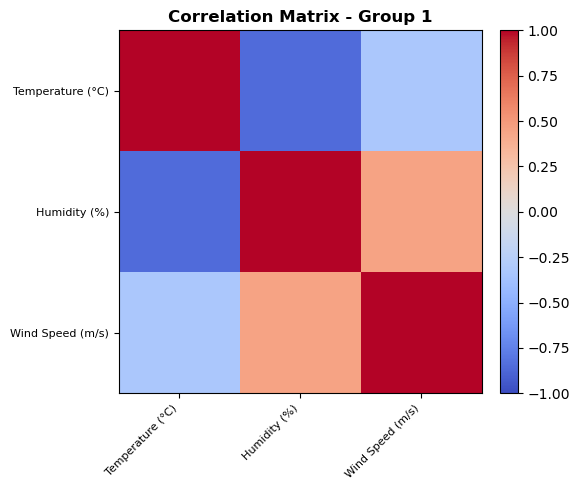

Saved Correlation Matrix - Group 1 to: D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Correlation_Matrix_Group_1.png


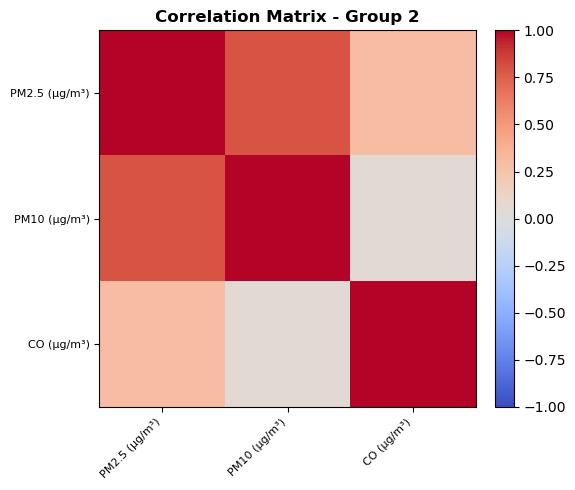

Saved Correlation Matrix - Group 2 to: D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Correlation_Matrix_Group_2.png


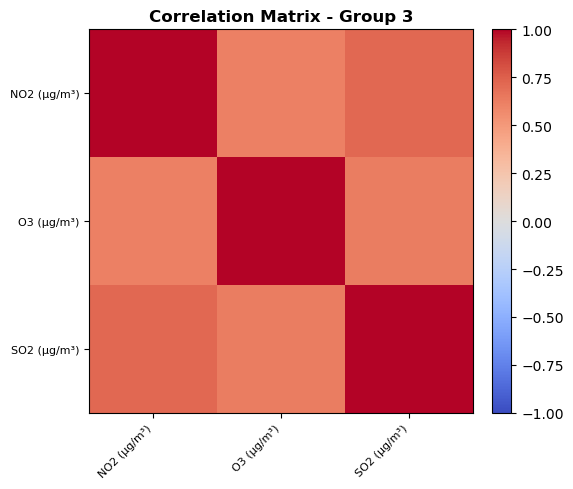

Saved Correlation Matrix - Group 3 to: D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Correlation_Matrix_Group_3.png


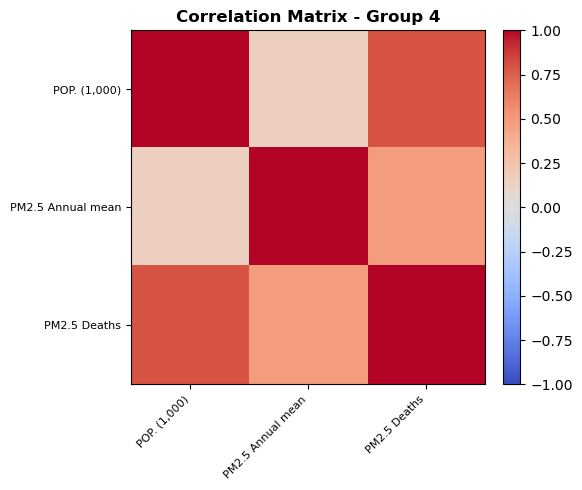

Saved Correlation Matrix - Group 4 to: D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Correlation_Matrix_Group_4.png


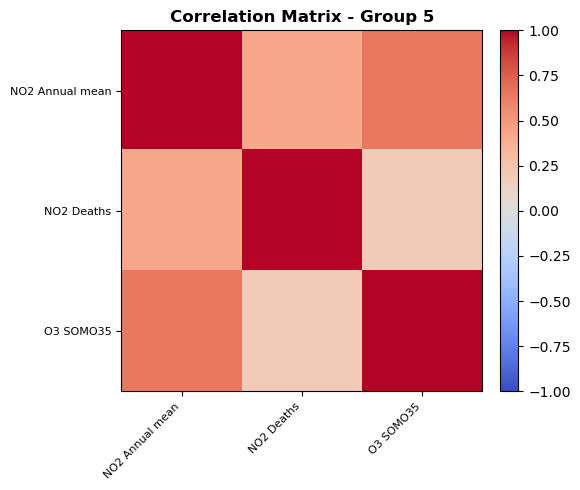

Saved Correlation Matrix - Group 5 to: D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Correlation_Matrix_Group_5.png


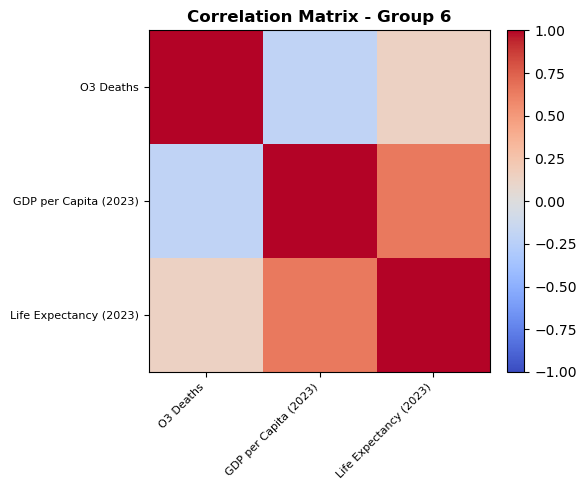

Saved Correlation Matrix - Group 6 to: D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Correlation_Matrix_Group_6.png


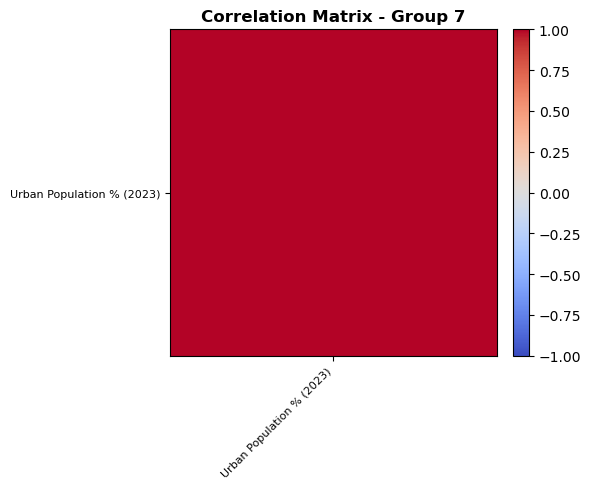

Saved Correlation Matrix - Group 7 to: D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Correlation_Matrix_Group_7.png

Correlation matrix images saved successfully to folder:
D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report


In [23]:
# Script to generate, display, and save correlation matrix images from the enriched dataset (Original Dataset Enriched.csv)
# Saves outputs as images in the specified folder and displays each heatmap
import pandas as pd
import matplotlib.pyplot as plt
import os

# === Load Enriched Dataset
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\Original Dataset Enriched.csv"
df = pd.read_csv(file_path)

# === Create output image folder if it doesn't exist
image_dir = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report"
os.makedirs(image_dir, exist_ok=True)

# === Select numeric columns only
numeric_cols = df.select_dtypes(include='number').columns.tolist()

# === Compute correlation matrix
corr_matrix = df[numeric_cols].corr()

# === Split correlation matrix columns into groups of 3 for readability
group_size = 3
col_groups = [numeric_cols[i:i + group_size] for i in range(0, len(numeric_cols), group_size)]

# === Function to save and show correlation heatmap
def save_and_show_corr_heatmap(corr_df, title, filename):
    plt.figure(figsize=(6, 5))
    plt.title(title, fontsize=12, weight='bold')
    heatmap = plt.imshow(corr_df, cmap='coolwarm', interpolation='nearest', vmin=-1, vmax=1)
    plt.colorbar(heatmap, fraction=0.046, pad=0.04)
    plt.xticks(range(len(corr_df.columns)), corr_df.columns, rotation=45, ha='right', fontsize=8)
    plt.yticks(range(len(corr_df.index)), corr_df.index, fontsize=8)
    plt.tight_layout()
    # Save image
    plt.savefig(filename, dpi=300)
    # Show the plot
    plt.show()
    # Close the figure
    plt.close()

# === Loop through each group of columns, create correlation submatrix, save, and show
for idx, group in enumerate(col_groups, start=1):
    corr_sub = corr_matrix.loc[group, group]
    
    filename = os.path.join(image_dir, f"Correlation_Matrix_Group_{idx}.png")
    save_and_show_corr_heatmap(corr_sub, f'Correlation Matrix - Group {idx}', filename)

    print(f"Saved Correlation Matrix - Group {idx} to: {filename}")

# === Confirm completion
print("\nCorrelation matrix images saved successfully to folder:")
print(image_dir)


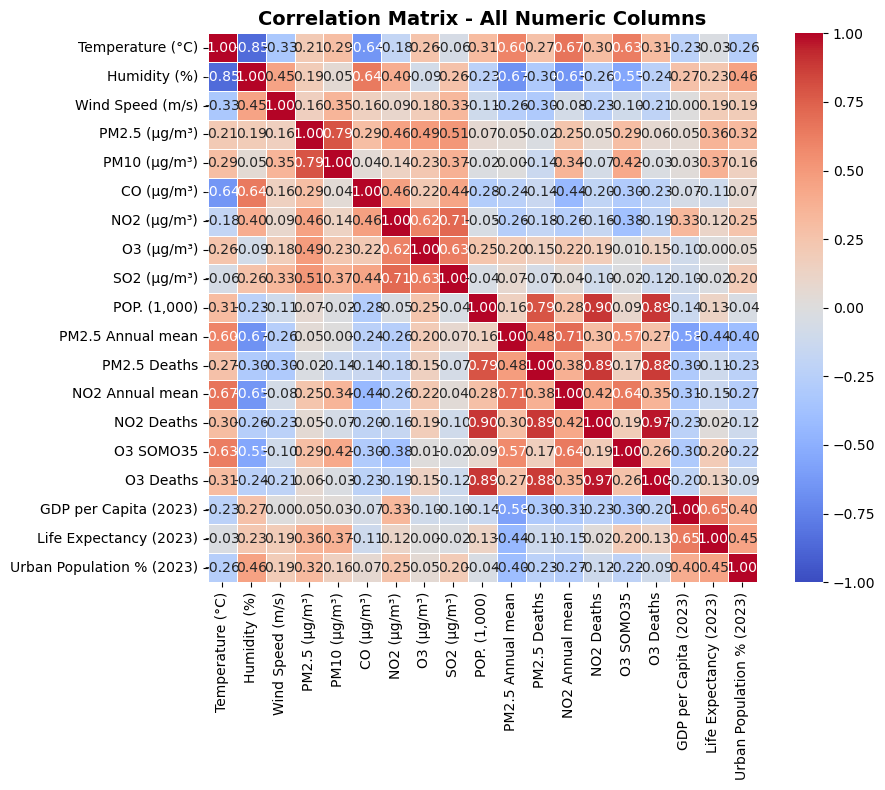


Strongly correlated variable pairs (|correlation| ≥ 0.75):

       Variable 1        Variable 2  Correlation
262    NO2 Deaths         O3 Deaths     0.965929
256    NO2 Deaths      POP. (1,000)     0.896183
294     O3 Deaths      POP. (1,000)     0.894676
258    NO2 Deaths      PM2.5 Deaths     0.888641
296     O3 Deaths      PM2.5 Deaths     0.881048
19   Humidity (%)  Temperature (°C)    -0.853899
218  PM2.5 Deaths      POP. (1,000)     0.793648
79   PM10 (µg/m³)     PM2.5 (µg/m³)     0.791678

Saved high-correlation pairs to: D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\High_Correlation_Pairs.csv


In [26]:
# ============================================================
#  High Correlation Detector and Correlation Heatmap
#  Shows full correlation matrix heatmap + strong correlations
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# === Load Enriched Dataset
file_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\Original Dataset Enriched.csv"
df = pd.read_csv(file_path)

# === Select numeric columns only
numeric_df = df.select_dtypes(include='number')

# === Compute correlation matrix
corr_matrix = numeric_df.corr()

# === Display correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Correlation Matrix - All Numeric Columns', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

# === Unstack matrix to get variable pairs
corr_pairs = corr_matrix.unstack()

# === Convert to DataFrame
corr_pairs_df = pd.DataFrame(corr_pairs, columns=['Correlation']).reset_index()
corr_pairs_df.columns = ['Variable 1', 'Variable 2', 'Correlation']

# === Filter out self-correlations and duplicate pairs
corr_pairs_df = corr_pairs_df[corr_pairs_df['Variable 1'] != corr_pairs_df['Variable 2']]
corr_pairs_df['AbsCorrelation'] = corr_pairs_df['Correlation'].abs()
corr_pairs_df = corr_pairs_df[corr_pairs_df['Variable 1'] < corr_pairs_df['Variable 2']]

# === Filter for strong correlations
threshold = 0.75
strong_corr_df = corr_pairs_df[corr_pairs_df['AbsCorrelation'] >= threshold].sort_values(by='AbsCorrelation', ascending=False)

# === Show strong correlations
if strong_corr_df.empty:
    print("\nNo variable pairs found with correlation ≥ 0.75.")
else:
    print("\nStrongly correlated variable pairs (|correlation| ≥ 0.75):\n")
    print(strong_corr_df[['Variable 1', 'Variable 2', 'Correlation']])

# === Save strong correlations to CSV
output_path = r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\High_Correlation_Pairs.csv"
strong_corr_df.to_csv(output_path, index=False)

print(f"\nSaved high-correlation pairs to: {output_path}")


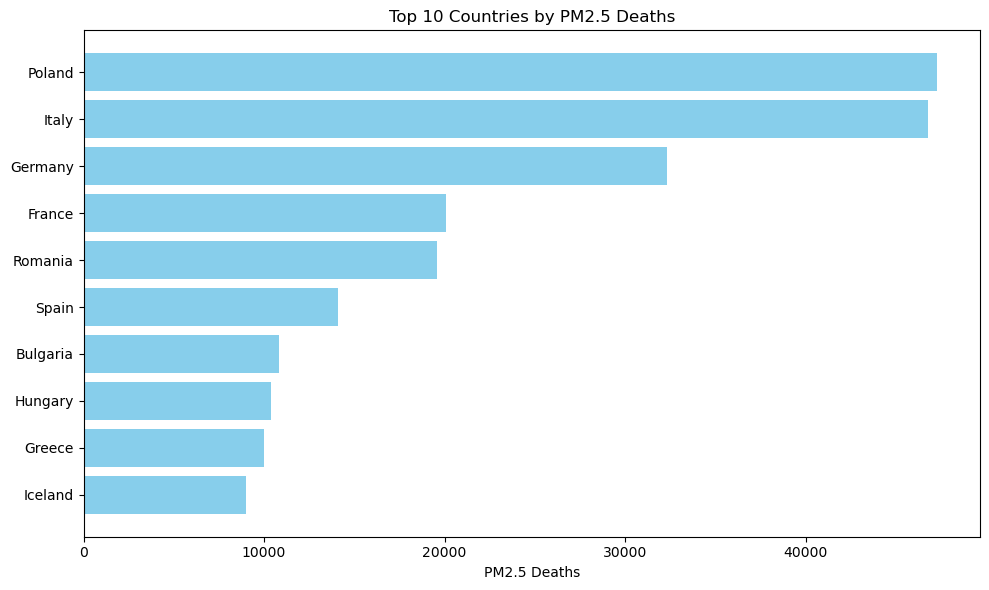

In [29]:
# Top 10 Countries by PM2.5 Deaths
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\Original Dataset Enriched.csv")

top_pm25 = df[['Country', 'PM2.5 Deaths']].sort_values(by='PM2.5 Deaths', ascending=False).head(10)

plt.figure(figsize=(10,6))
plt.barh(top_pm25['Country'], top_pm25['PM2.5 Deaths'], color='skyblue')
plt.xlabel('PM2.5 Deaths')
plt.title('Top 10 Countries by PM2.5 Deaths')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Imegies for Report\Top10_PM25_Deaths.png", dpi=300)
plt.show()


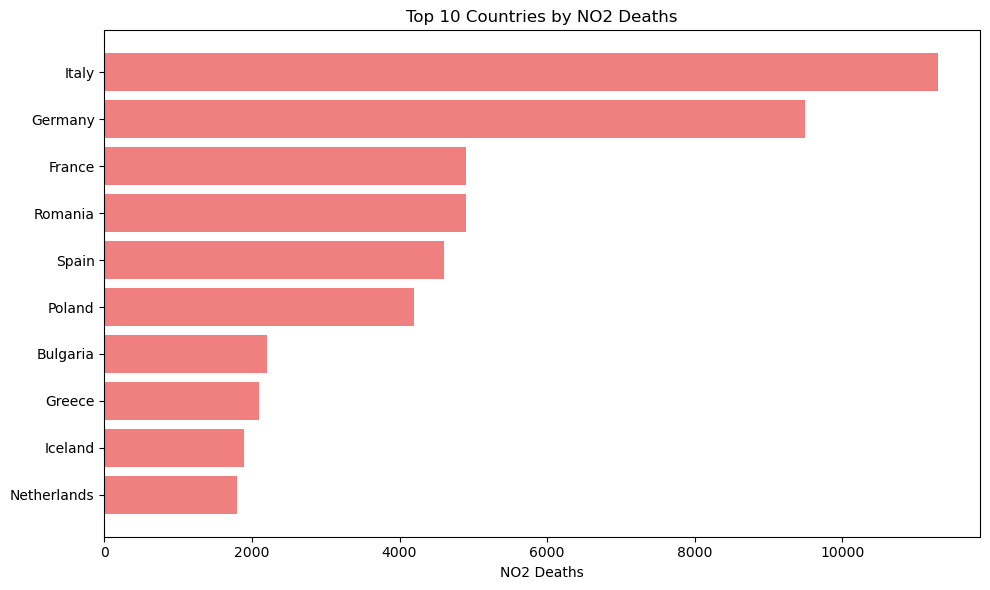

In [30]:
# Top 10 Countries by NO2 Deaths
top_no2 = df[['Country', 'NO2 Deaths']].sort_values(by='NO2 Deaths', ascending=False).head(10)

plt.figure(figsize=(10,6))
plt.barh(top_no2['Country'], top_no2['NO2 Deaths'], color='lightcoral')
plt.xlabel('NO2 Deaths')
plt.title('Top 10 Countries by NO2 Deaths')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Imegies for Report\Top10_NO2_Deaths.png", dpi=300)
plt.show()


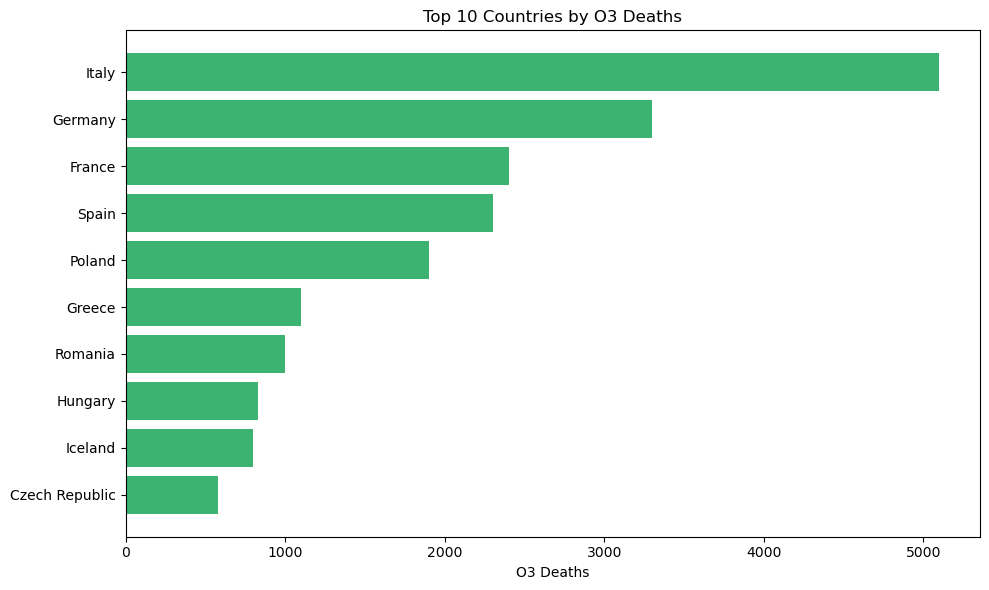

In [31]:
# Top 10 Countries by O3 Deaths
top_o3 = df[['Country', 'O3 Deaths']].sort_values(by='O3 Deaths', ascending=False).head(10)

plt.figure(figsize=(10,6))
plt.barh(top_o3['Country'], top_o3['O3 Deaths'], color='mediumseagreen')
plt.xlabel('O3 Deaths')
plt.title('Top 10 Countries by O3 Deaths')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Imegies for Report\Top10_O3_Deaths.png", dpi=300)
plt.show()


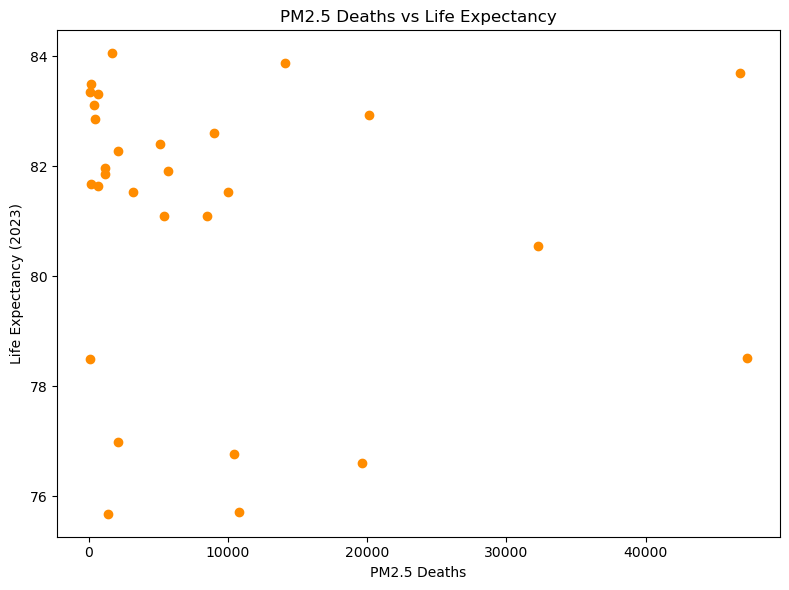

In [32]:
# Scatter Plot: PM2.5 Deaths vs Life Expectancy
plt.figure(figsize=(8,6))
plt.scatter(df['PM2.5 Deaths'], df['Life Expectancy (2023)'], color='darkorange')
plt.xlabel('PM2.5 Deaths')
plt.ylabel('Life Expectancy (2023)')
plt.title('PM2.5 Deaths vs Life Expectancy')
plt.tight_layout()
plt.savefig(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Imegies for Report\Scatter_PM25_vs_LifeExpectancy.png", dpi=300)
plt.show()


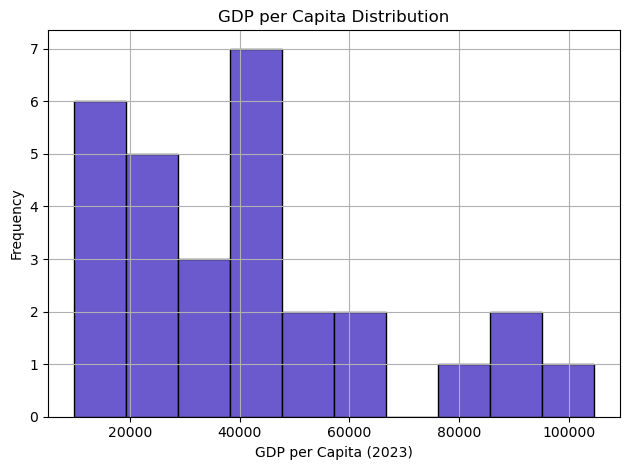

In [33]:
# Histogram of GDP per Capita
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\Original Dataset Enriched.csv")

df['GDP per Capita (2023)'].hist(bins=10, edgecolor='black', color='slateblue')
plt.title('GDP per Capita Distribution')
plt.xlabel('GDP per Capita (2023)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Imegies for Report\Histogram_GDP_Per_Capita.png", dpi=300)
plt.show()


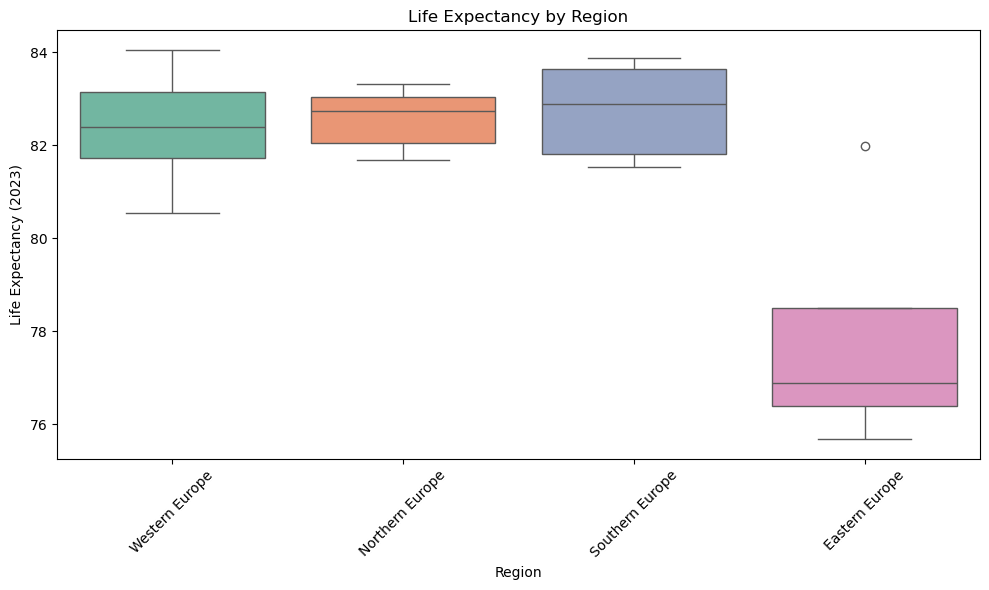

In [40]:
# Boxplot of Life Expectancy by Region (fixed for Seaborn future deprecation)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\Original Dataset Enriched.csv")

plt.figure(figsize=(10,6))
sns.boxplot(
    x='Region',
    y='Life Expectancy (2023)',
    hue='Region',
    data=df,
    palette='Set2',
    dodge=False # keep boxes centered per region
)
plt.title('Life Expectancy by Region')
plt.xlabel('Region')
plt.ylabel('Life Expectancy (2023)')
plt.xticks(rotation=45)
plt.legend().remove()
plt.tight_layout()
plt.savefig(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Imegies for Report\Boxplot_Life_Expectancy_by_Region.png", dpi=300)
plt.show()


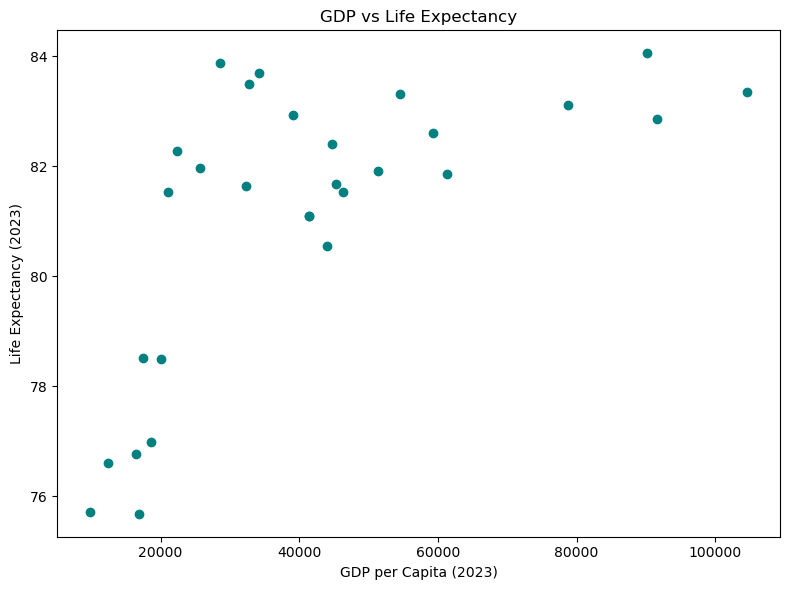

In [35]:
# Scatter Plot: GDP vs Life Expectancy
plt.figure(figsize=(8,6))
plt.scatter(df['GDP per Capita (2023)'], df['Life Expectancy (2023)'], color='teal')
plt.xlabel('GDP per Capita (2023)')
plt.ylabel('Life Expectancy (2023)')
plt.title('GDP vs Life Expectancy')
plt.tight_layout()
plt.savefig(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Imegies for Report\Scatter_GDP_vs_LifeExpectancy.png", dpi=300)
plt.show()


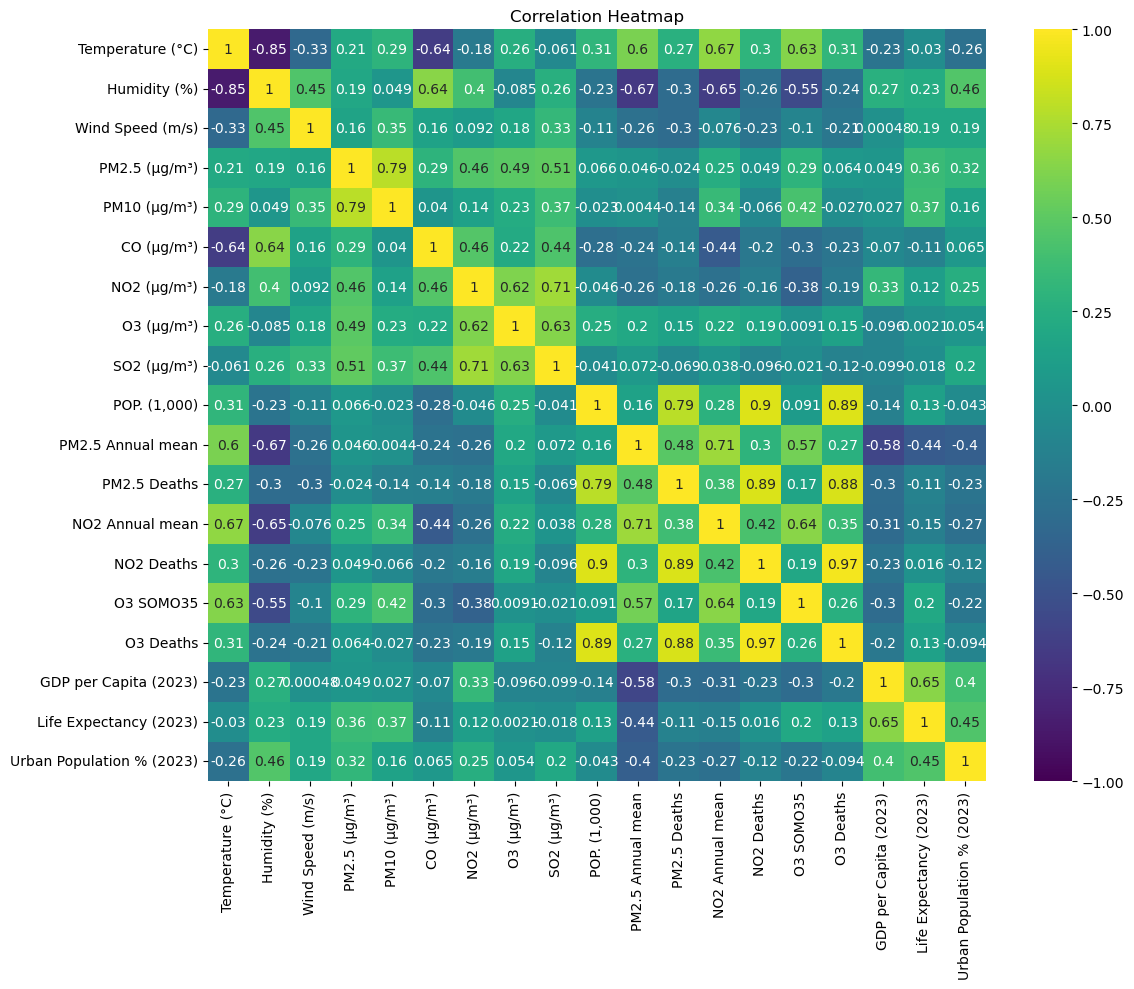

In [36]:
# Correlation Heatmap
corr = df.select_dtypes(include='number').corr()

plt.figure(figsize=(12,10))
sns.heatmap(corr, annot=True, cmap='viridis', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Imegies for Report\Correlation_Heatmap.png", dpi=300)
plt.show()


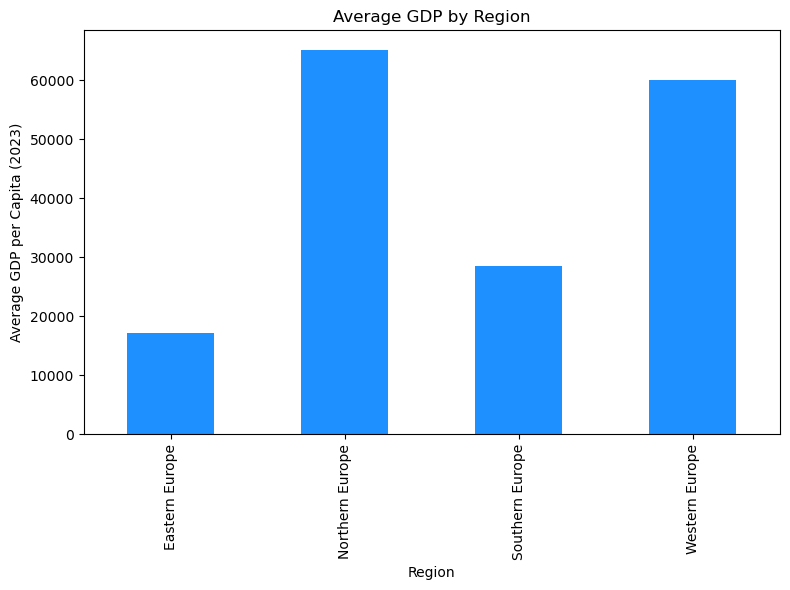

In [37]:
# Bar Plot: Average GDP by Region
avg_gdp = df.groupby('Region')['GDP per Capita (2023)'].mean()

plt.figure(figsize=(8,6))
avg_gdp.plot(kind='bar', color='dodgerblue')
plt.ylabel('Average GDP per Capita (2023)')
plt.title('Average GDP by Region')
plt.tight_layout()
plt.savefig(r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Imegies for Report\Barplot_Avg_GDP_by_Region.png", dpi=300)
plt.show()


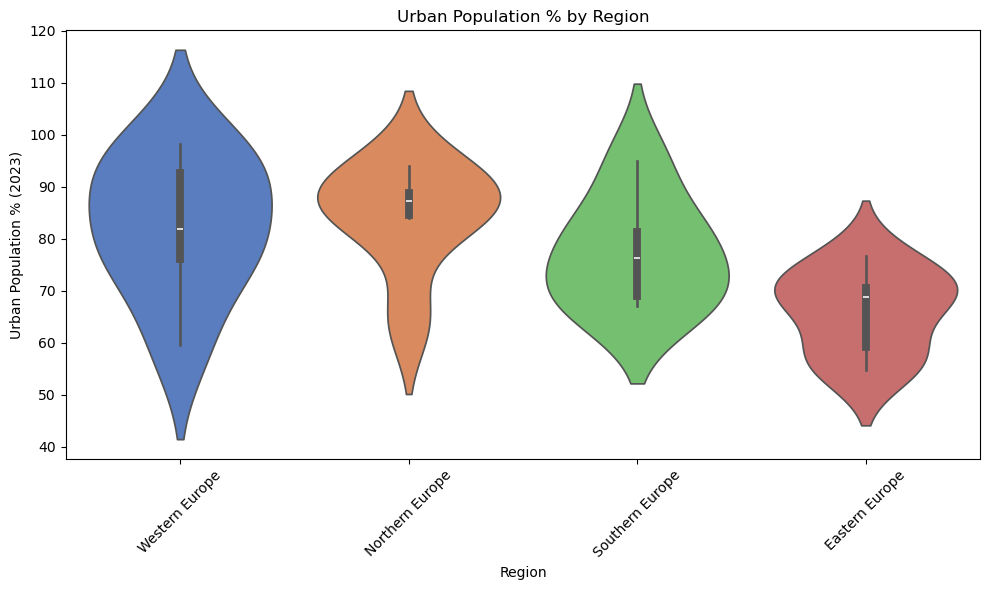

In [41]:
# Violin Plot: Urban Population by Region (fixed hue warning)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\Original Dataset Enriched.csv"
)

plt.figure(figsize=(10,6))
sns.violinplot(
    x='Region',
    y='Urban Population % (2023)',
    hue='Region',
    data=df,
    palette='muted',
    dodge=False
)
plt.title('Urban Population % by Region')
plt.xlabel('Region')
plt.ylabel('Urban Population % (2023)')
plt.xticks(rotation=45)
plt.legend().remove()
plt.tight_layout()
plt.savefig(
    r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Imegies for Report\Violin_Urban_Population_by_Region.png",
    dpi=300
)
plt.show()


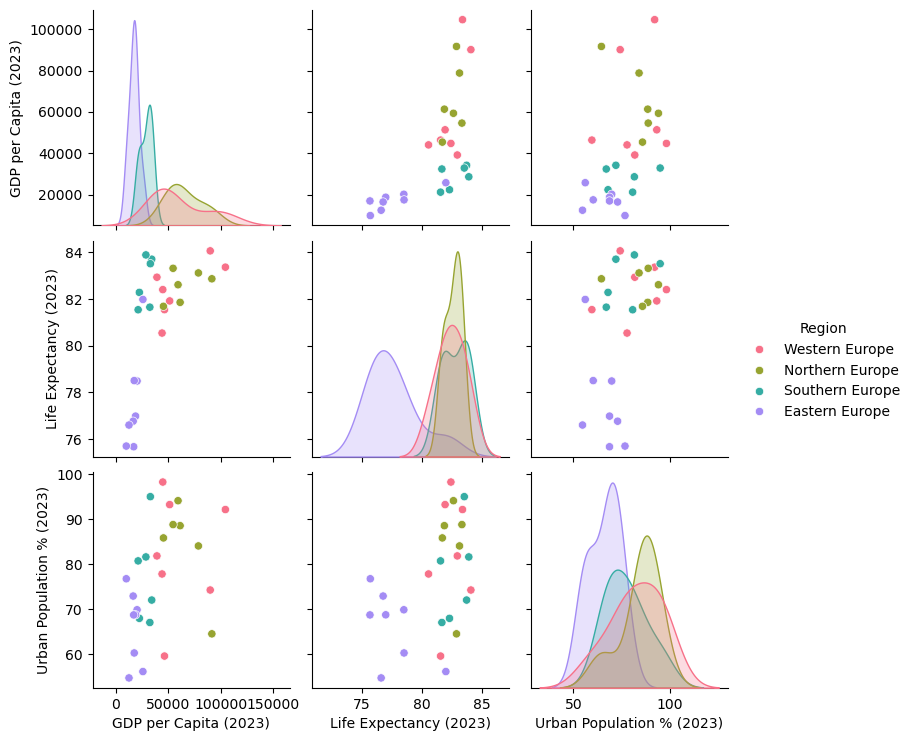

In [42]:
# Pair Plot with hue='Region' to remove warnings
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Final Final Final Project\Original Dataset Enriched.csv"
)

sns.pairplot(
    df,
    vars=[
        'GDP per Capita (2023)',
        'Life Expectancy (2023)',
        'Urban Population % (2023)'
    ],
    hue='Region',
    diag_kind='kde',
    palette='husl'
)

plt.savefig(
    r"D:\University of Bicocca\Data science\1st year 2024-25\1st semister 1year\DM Data management\Images for Report\Imegies for Report\Pairplot_Selected_Variables.png",
    dpi=300
)
plt.show()
